# MT5 Data Fetcher + Local CSV Loader

This notebook can either:

1. Fetch fresh OHLC data from MetaTrader 5
2. Load previously saved OHLC data from a local CSV file

It supports three MT5 fetch modes:

- `last_n`
- `date_range`
- `max_bars`

The `max_bars` function is kept in the simple original form:

```python
rates = mt5.copy_rates_from_pos(symbol, timeframe, 0, max_bars_request)
```

The output DataFrame keeps these columns:

- `time`
- `open`
- `high`
- `low`
- `close`
- `tick_volume`
- `spread`
- `real_volume`
- `range`
- `body`
- `weekday`
- `ema20`
- `atr14`

It does not include separate `date`, `hour`, `minute`, `upper_wick`, `lower_wick`, or `range_pct` columns.


## 1. Optional package installation

Run this only if packages are missing from your active Python environment.


In [29]:
# Run only if needed.
# import sys
# !{sys.executable} -m pip install MetaTrader5 pandas matplotlib


## 2. Imports and configuration

Change the settings below.

Use:

```python
USE_LOCAL_CSV = True
```

when you want to load saved data from CSV.

Use:

```python
USE_LOCAL_CSV = False
```

when you want to fetch fresh data from MT5.


In [30]:
import MetaTrader5 as mt5
import pandas as pd
from datetime import datetime, timezone
from pathlib import Path


# ============================================================
# CHOOSE DATA SOURCE
# ============================================================

# True  -> load df from local CSV
# False -> fetch df from MT5
USE_LOCAL_CSV = True

# Used only when USE_LOCAL_CSV = True
CSV_FILE_PATH = r"mt5_data\XAUUSDzero_M5_max_bars.csv"


# ============================================================
# MT5 TERMINAL CONFIG
# ============================================================

MT5_PATH = r"C:\Program Files\AMarkets - MetaTrader 5\terminal64.exe"


# ============================================================
# DATA CONFIG
# ============================================================

SYMBOL = "XAUUSDzero"
TIMEFRAME_NAME = "M5"

TIMEFRAMES = {
    "M1": mt5.TIMEFRAME_M1,
    "M2": mt5.TIMEFRAME_M2,
    "M3": mt5.TIMEFRAME_M3,
    "M4": mt5.TIMEFRAME_M4,
    "M5": mt5.TIMEFRAME_M5,
    "M6": mt5.TIMEFRAME_M6,
    "M10": mt5.TIMEFRAME_M10,
    "M12": mt5.TIMEFRAME_M12,
    "M15": mt5.TIMEFRAME_M15,
    "M20": mt5.TIMEFRAME_M20,
    "M30": mt5.TIMEFRAME_M30,
    "H1": mt5.TIMEFRAME_H1,
    "H2": mt5.TIMEFRAME_H2,
    "H3": mt5.TIMEFRAME_H3,
    "H4": mt5.TIMEFRAME_H4,
    "H6": mt5.TIMEFRAME_H6,
    "H8": mt5.TIMEFRAME_H8,
    "H12": mt5.TIMEFRAME_H12,
    "D1": mt5.TIMEFRAME_D1,
    "W1": mt5.TIMEFRAME_W1,
    "MN1": mt5.TIMEFRAME_MN1,
}

TIMEFRAME = TIMEFRAMES[TIMEFRAME_NAME]


# ============================================================
# MT5 FETCH MODE
# ============================================================
# Used only when USE_LOCAL_CSV = False
#
# Choose one:
# "last_n"      -> fetch latest N candles
# "date_range"  -> fetch from START_DATE to END_DATE
# "max_bars"    -> ask MT5 for MAX_BARS_REQUEST bars

FETCH_MODE = "last_n"


# Used when FETCH_MODE = "last_n"
LAST_N_CANDLES = 10_000


# Used when FETCH_MODE = "date_range"
START_DATE = datetime(2025, 1, 1, 0, 0, tzinfo=timezone.utc)
END_DATE = datetime(2025, 12, 31, 23, 59, tzinfo=timezone.utc)


# Used when FETCH_MODE = "max_bars"
MAX_BARS_REQUEST = 1_000_000


# ============================================================
# OUTPUT CONFIG
# ============================================================

OUTPUT_DIR = Path("mt5_data")
OUTPUT_DIR.mkdir(exist_ok=True)

SAVE_CSV = True


## 3. Helper functions


In [31]:
def connect_to_mt5(mt5_path: str) -> None:
    """Connect to a specific MetaTrader 5 terminal."""
    if not mt5.initialize(path=mt5_path):
        raise RuntimeError(f"MT5 initialize failed: {mt5.last_error()}")

    terminal_info = mt5.terminal_info()
    account_info = mt5.account_info()

    print("Connected to MetaTrader 5")
    print(f"Terminal path: {terminal_info.path}")
    print(f"Terminal name: {terminal_info.name}")
    print(f"Company: {terminal_info.company}")
    print(f"Data path: {terminal_info.data_path}")

    if account_info:
        print(f"Account login: {account_info.login}")
        print(f"Server: {account_info.server}")
        print(f"Account company: {account_info.company}")

    print("-" * 80)


def validate_symbol(symbol: str) -> None:
    """Check that the symbol exists and select it in Market Watch."""
    symbol_info = mt5.symbol_info(symbol)

    if symbol_info is None:
        print(f"Symbol not found: {symbol}")
        print("Similar gold/XAU symbols available:")

        symbols = mt5.symbols_get()
        if symbols:
            for s in symbols:
                name_upper = s.name.upper()
                if "XAU" in name_upper or "GOLD" in name_upper:
                    print(" -", s.name)

        raise RuntimeError(f"Symbol does not exist in this terminal: {symbol}")

    if not mt5.symbol_select(symbol, True):
        raise RuntimeError(f"Could not select symbol: {symbol}. MT5 error: {mt5.last_error()}")

    symbol_info = mt5.symbol_info(symbol)

    print(f"Symbol selected: {symbol_info.name}")
    print(f"Visible: {symbol_info.visible}")
    print(f"Digits: {symbol_info.digits}")
    print(f"Point: {symbol_info.point}")
    print("-" * 80)


def add_candle_features(df: pd.DataFrame) -> pd.DataFrame:
    """Add candle range/body, weekday, EMA20, and ATR14."""
    df = df.copy()

    df["range"] = df["high"] - df["low"]
    df["body"] = (df["close"] - df["open"]).abs()
    df["weekday"] = df["time"].dt.day_name()

    # EMA 20 based on close.
    df["ema20"] = df["close"].ewm(span=20, adjust=False).mean()

    # ATR 14.
    prev_close = df["close"].shift(1)
    high_low = df["high"] - df["low"]
    high_prev_close = (df["high"] - prev_close).abs()
    low_prev_close = (df["low"] - prev_close).abs()

    true_range = pd.concat(
        [high_low, high_prev_close, low_prev_close],
        axis=1
    ).max(axis=1)

    # Wilder-style ATR uses alpha = 1 / period.
    df["atr14"] = true_range.ewm(alpha=1 / 14, adjust=False).mean()

    return df


def clean_dataframe_columns(df: pd.DataFrame) -> pd.DataFrame:
    """Sort, de-duplicate, recalculate features, and keep the final columns."""
    df = df.copy()

    if "time" not in df.columns:
        raise ValueError("DataFrame must contain a 'time' column.")

    df["time"] = pd.to_datetime(df["time"], utc=True)

    required_price_columns = ["open", "high", "low", "close"]
    missing_columns = [col for col in required_price_columns if col not in df.columns]

    if missing_columns:
        raise ValueError(f"Missing required price columns: {missing_columns}")

    df = (
        df
        .sort_values("time")
        .drop_duplicates(subset=["time"])
        .reset_index(drop=True)
    )

    df = add_candle_features(df)

    desired_columns = [
        "time",
        "open",
        "high",
        "low",
        "close",
        "tick_volume",
        "spread",
        "real_volume",
        "range",
        "body",
        "weekday",
        "ema20",
        "atr14",
    ]

    existing_columns = [col for col in desired_columns if col in df.columns]
    df = df[existing_columns]

    return df


def convert_rates_to_dataframe(rates) -> pd.DataFrame:
    """Convert MT5 rates array to a clean pandas DataFrame."""
    if rates is None:
        raise RuntimeError(f"MT5 returned None. Error: {mt5.last_error()}")

    if len(rates) == 0:
        raise RuntimeError("MT5 returned 0 rows. Try a smaller date range or load more chart history.")

    df = pd.DataFrame(rates)
    df["time"] = pd.to_datetime(df["time"], unit="s", utc=True)

    return clean_dataframe_columns(df)


def load_dataframe_from_csv(csv_file_path: str) -> pd.DataFrame:
    """
    Load previously saved MT5 candle data from a local CSV file.

    The CSV should contain at least:
    time, open, high, low, close

    If range/body/weekday/ema20/atr14 already exist, they are recalculated.
    """
    df = pd.read_csv(csv_file_path)
    return clean_dataframe_columns(df)


def fetch_last_n_candles(symbol: str, timeframe: int, n_candles: int) -> pd.DataFrame:
    """Fetch the latest N candles."""
    rates = mt5.copy_rates_from_pos(symbol, timeframe, 0, n_candles)
    return convert_rates_to_dataframe(rates)


def fetch_date_range(symbol: str, timeframe: int, start_date: datetime, end_date: datetime) -> pd.DataFrame:
    """Fetch candles from start_date to end_date. Dates should be timezone-aware UTC datetimes."""
    rates = mt5.copy_rates_range(symbol, timeframe, start_date, end_date)
    return convert_rates_to_dataframe(rates)


def fetch_max_available_bars(symbol: str, timeframe: int, max_bars_request: int) -> pd.DataFrame:
    """
    Try to fetch the maximum available bars.

    This asks MT5 for a large number of bars from the latest candle backward.
    The terminal/broker may return less than requested.
    """
    rates = mt5.copy_rates_from_pos(symbol, timeframe, 0, max_bars_request)
    return convert_rates_to_dataframe(rates)


def fetch_data(
    mode: str,
    symbol: str,
    timeframe: int,
    last_n_candles: int = 10_000,
    start_date: datetime = None,
    end_date: datetime = None,
    max_bars_request: int = 1_000_000,
) -> pd.DataFrame:
    """Main fetch function with three supported modes."""
    if mode == "last_n":
        print(f"Fetching latest {last_n_candles:,} candles for {symbol}...")
        return fetch_last_n_candles(symbol, timeframe, last_n_candles)

    if mode == "date_range":
        if start_date is None or end_date is None:
            raise ValueError("start_date and end_date are required for mode='date_range'.")

        print(f"Fetching {symbol} from {start_date} to {end_date}...")
        return fetch_date_range(symbol, timeframe, start_date, end_date)

    if mode == "max_bars":
        print(f"Trying to fetch up to {max_bars_request:,} bars for {symbol}...")
        return fetch_max_available_bars(symbol, timeframe, max_bars_request)

    raise ValueError("Invalid mode. Use 'last_n', 'date_range', or 'max_bars'.")


def save_dataframe_to_csv(df: pd.DataFrame, symbol: str, timeframe_name: str, fetch_mode: str) -> Path:
    """Save fetched or loaded data to CSV."""
    output_file = OUTPUT_DIR / f"{symbol}_{timeframe_name}_{fetch_mode}.csv"
    df.to_csv(output_file, index=False)
    return output_file


## 4. Load from CSV or fetch from MT5

Run this cell to create the main DataFrame named `df`.

All later analysis cells use this same `df`, whether it came from CSV or MT5.


In [32]:
if USE_LOCAL_CSV:
    print(f"Loading data from CSV: {CSV_FILE_PATH}")

    df = load_dataframe_from_csv(CSV_FILE_PATH)

    print("CSV loaded.")
    print(f"Rows: {len(df):,}")
    print(f"First candle: {df['time'].min()}")
    print(f"Last candle: {df['time'].max()}")

else:
    connect_to_mt5(MT5_PATH)
    validate_symbol(SYMBOL)

    try:
        df = fetch_data(
            mode=FETCH_MODE,
            symbol=SYMBOL,
            timeframe=TIMEFRAME,
            last_n_candles=LAST_N_CANDLES,
            start_date=START_DATE,
            end_date=END_DATE,
            max_bars_request=MAX_BARS_REQUEST,
        )

        print("Fetch complete.")
        print(f"Rows: {len(df):,}")
        print(f"First candle: {df['time'].min()}")
        print(f"Last candle: {df['time'].max()}")

        if SAVE_CSV:
            output_file = save_dataframe_to_csv(df, SYMBOL, TIMEFRAME_NAME, FETCH_MODE)
            print(f"Saved to: {output_file}")

    finally:
        mt5.shutdown()
        print("MT5 connection closed.")


Loading data from CSV: mt5_data\XAUUSDzero_M5_max_bars.csv
CSV loaded.
Rows: 90,000
First candle: 2025-02-10 21:45:00+00:00
Last candle: 2026-05-20 12:30:00+00:00


## 5. Preview the data


In [33]:
df.head()


,time,open,high,low,close,tick_volume,spread,real_volume,range,body,weekday,ema20,atr14
0,2025-02-10 21:45:00+00:00,2904.95,2905.42,2904.60,2904.60,502,0,0,0.82,0.35,Monday,2904.600000,0.820000
1,2025-02-10 21:50:00+00:00,2904.64,2904.74,2903.43,2903.68,679,0,0,1.31,0.96,Monday,2904.512381,0.855000
2,2025-02-10 21:55:00+00:00,2903.64,2904.55,2903.34,2904.41,711,0,0,1.21,0.77,Monday,2904.502630,0.880357
3,2025-02-10 22:00:00+00:00,2904.40,2904.94,2903.67,2904.04,673,0,0,1.27,0.36,Monday,2904.458570,0.908189
4,2025-02-10 22:05:00+00:00,2904.05,2904.42,2903.48,2903.54,634,0,0,0.94,0.51,Monday,2904.371087,0.910461


In [34]:
df.tail()


,time,open,high,low,close,tick_volume,spread,real_volume,range,body,weekday,ema20,atr14
89995,2026-05-20 12:10:00+00:00,4482.19,4482.51,4479.93,4480.36,419,0,0,2.58,1.83,Wednesday,4481.744043,5.254938
89996,2026-05-20 12:15:00+00:00,4480.09,4482.60,4479.23,4482.60,419,0,0,3.37,2.51,Wednesday,4481.825562,5.120300
89997,2026-05-20 12:20:00+00:00,4482.63,4483.69,4478.91,4479.50,381,0,0,4.78,3.13,Wednesday,4481.604080,5.095993
89998,2026-05-20 12:25:00+00:00,4479.46,4479.61,4473.02,4474.29,434,0,0,6.59,5.17,Wednesday,4480.907501,5.202708
89999,2026-05-20 12:30:00+00:00,4474.20,4480.05,4473.01,4479.87,267,1,0,7.04,5.67,Wednesday,4480.808692,5.333943


## 6. Quick checks


In [35]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90000 entries, 0 to 89999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype              
---  ------       --------------  -----              
 0   time         90000 non-null  datetime64[ns, UTC]
 1   open         90000 non-null  float64            
 2   high         90000 non-null  float64            
 3   low          90000 non-null  float64            
 4   close        90000 non-null  float64            
 5   tick_volume  90000 non-null  int64              
 6   spread       90000 non-null  int64              
 7   real_volume  90000 non-null  int64              
 8   range        90000 non-null  float64            
 9   body         90000 non-null  float64            
 10  weekday      90000 non-null  object             
 11  ema20        90000 non-null  float64            
 12  atr14        90000 non-null  float64            
dtypes: datetime64[ns, UTC](1), float64(8), int64(3), object(1)
memory usage: 8.9

In [36]:
df.describe()


,open,high,low,close,tick_volume,spread,real_volume,range,body,ema20,atr14
count,90000.000000,90000.000000,90000.000000,90000.000000,90000.000000,90000.000000,90000.0,90000.000000,90000.000000,90000.000000,90000.000000
mean,3909.833531,3912.077878,3907.479090,3909.849954,530.380733,1.006033,0.0,4.598788,2.332318,3909.683576,4.611456
std,707.389448,708.390178,706.293053,707.380761,200.679631,3.612566,0.0,4.929040,3.388843,707.371236,3.870447
min,2833.740000,2836.890000,2832.760000,2833.890000,12.000000,0.000000,0.0,0.150000,0.000000,2842.819154,0.636371
25%,3327.170000,3328.490000,3325.880000,3327.190000,392.000000,0.000000,0.0,1.990000,0.580000,3327.452931,2.358829
50%,3815.725000,3817.385000,3813.675000,3815.780000,511.000000,0.000000,0.0,3.250000,1.360000,3814.416444,3.609285
75%,4555.335000,4558.760000,4551.902500,4555.395000,650.000000,0.000000,0.0,5.460000,2.830000,4555.657237,5.547850
max,5588.180000,5596.760000,5581.740000,5588.560000,1561.000000,66.000000,0.0,208.740000,123.020000,5570.422378,61.179895


## 7. Average candle range by weekday

This table groups candles by weekday and summarizes the `range` column.

```python
range = high - low
```

Column meanings:

- `count`: number of candles in that weekday group
- `mean`: average candle range
- `median`: middle candle range
- `std`: standard deviation of candle ranges
- `min`: smallest candle range
- `max`: largest candle range


In [37]:
weekday_stats = (
    df.groupby("weekday")["range"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .sort_values("mean", ascending=False)
)

weekday_stats


,count,mean,median,std,min,max
weekday,,,,,,
Monday,18093,4.883955,3.31,5.756924,0.24,137.82
Thursday,17592,4.678017,3.29,5.330482,0.28,208.74
Friday,17528,4.641848,3.22,5.149472,0.15,91.83
Tuesday,18492,4.453368,3.21,4.314929,0.17,91.07
Wednesday,18295,4.346315,3.23,3.876529,0.16,65.31


## 8. Candle range distribution

This gives percentile levels for candle range.


In [38]:
range_distribution = df["range"].quantile([
    0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99
]).to_frame(name="range")

range_distribution


,range
0.01,0.6600
0.05,1.0100
0.10,1.3000
0.25,1.9900
0.50,3.2500
0.75,5.4600
0.90,8.9000
0.95,12.2700
0.99,24.4101


## 9. Optional plots


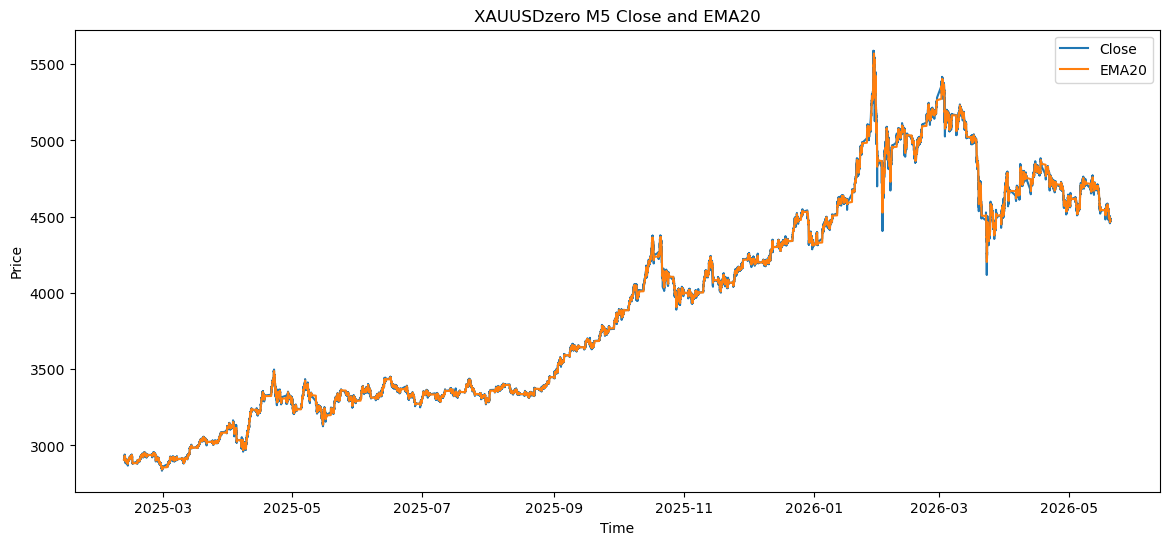

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))
plt.plot(df["time"], df["close"], label="Close")
plt.plot(df["time"], df["ema20"], label="EMA20")
plt.title(f"{SYMBOL} {TIMEFRAME_NAME} Close and EMA20")
plt.xlabel("Time")
plt.ylabel("Price")
plt.legend()
plt.show()


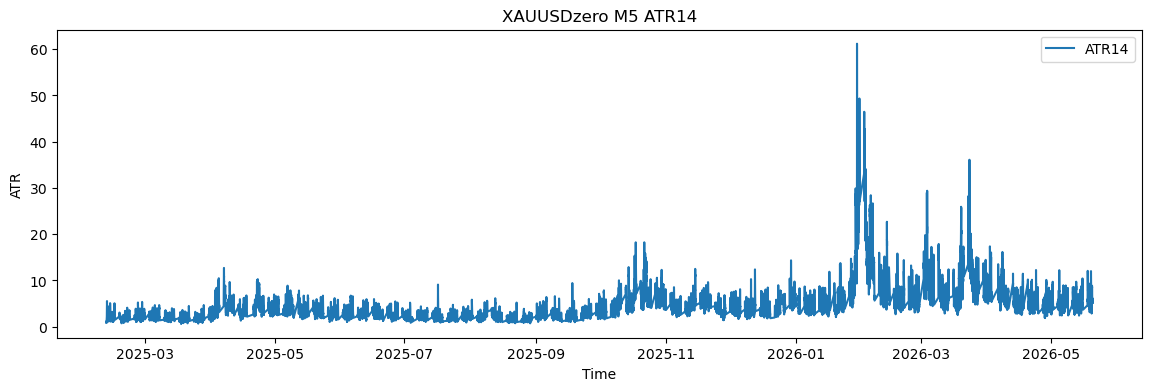

In [40]:
plt.figure(figsize=(14, 4))
plt.plot(df["time"], df["atr14"], label="ATR14")
plt.title(f"{SYMBOL} {TIMEFRAME_NAME} ATR14")
plt.xlabel("Time")
plt.ylabel("ATR")
plt.legend()
plt.show()


## 10. Notes

- When `USE_LOCAL_CSV = True`, no MT5 connection is opened.
- When `USE_LOCAL_CSV = False`, the notebook fetches fresh data from MT5.
- CSV loading recalculates `range`, `body`, `weekday`, `ema20`, and `atr14` to keep them consistent.
- The simple `max_bars` mode can fail if `MAX_BARS_REQUEST` is too large for the terminal to handle in one request. Lower `MAX_BARS_REQUEST` if needed.


## Gold M5 Session Volatility & Candle Quality Analyzer

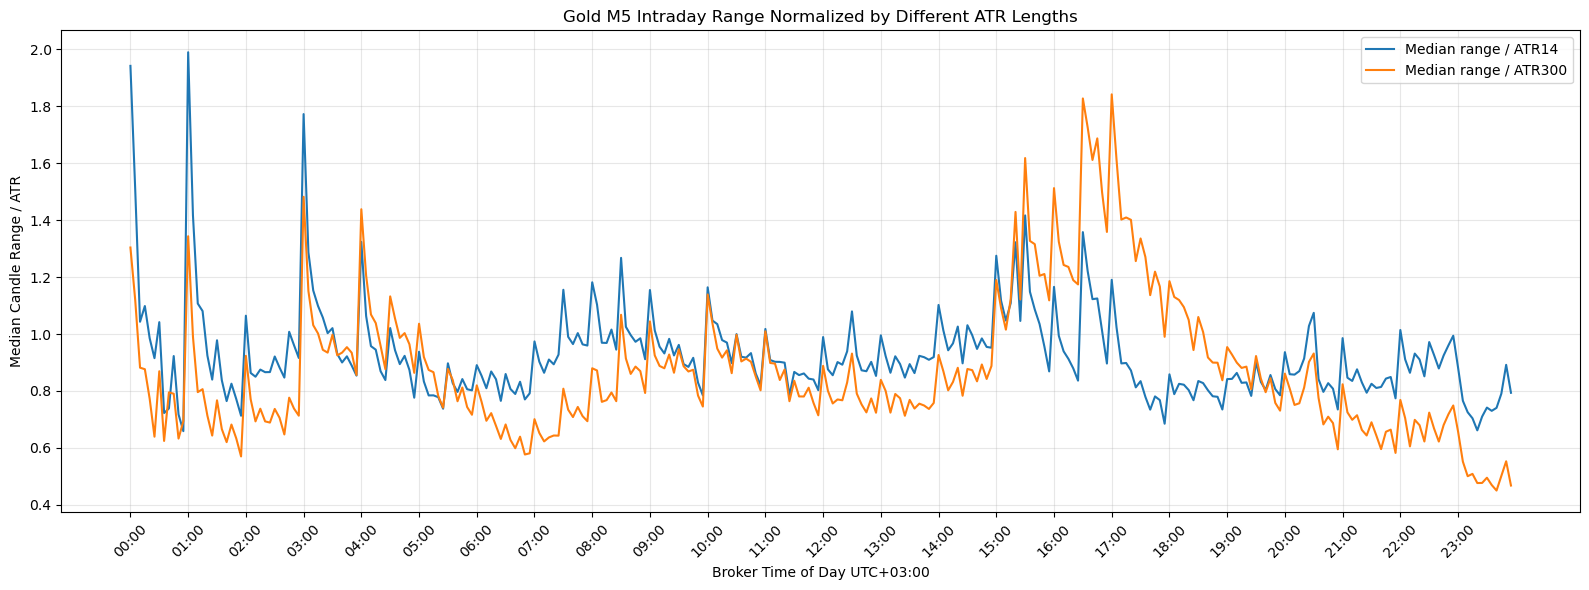

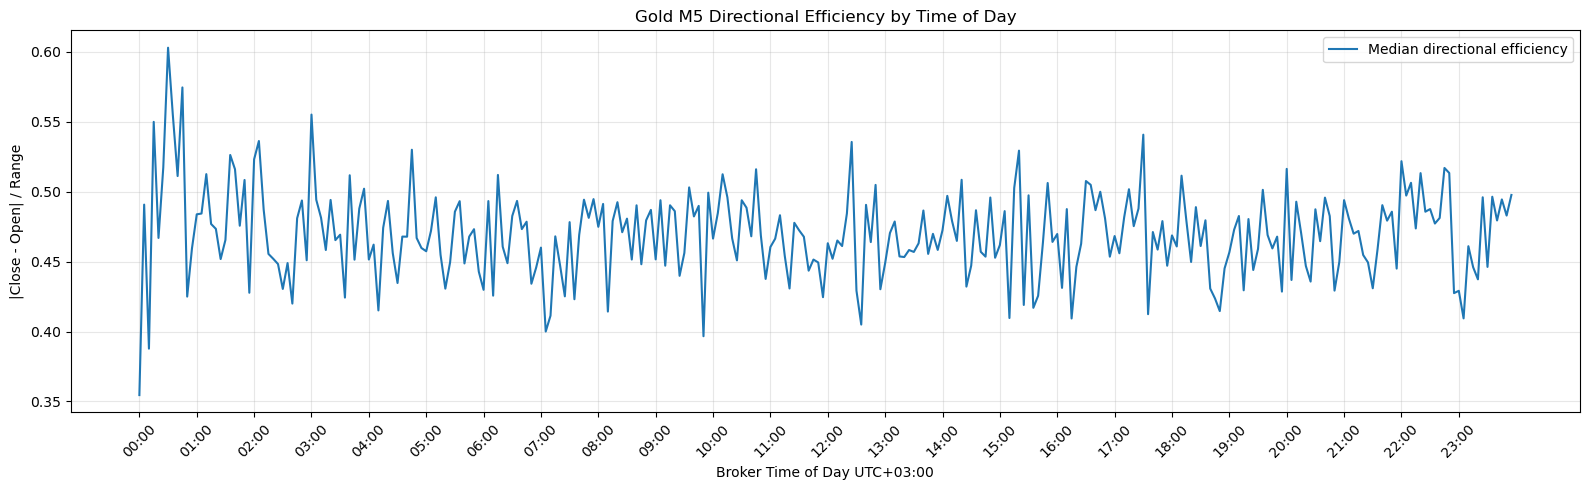

,candles,median_range_atr300,mean_range_atr300,p75_range_atr300,p90_range_atr300,median_directional_efficiency,median_wick_ratio,median_tick_volume,mean_tick_volume
session,,,,,,,,,
London-NY overlap,9780,1.237780,1.415518,1.720583,2.321316,0.471278,0.528722,667.0,703.816462
London,17611,0.917535,1.069642,1.286921,1.779877,0.463442,0.536558,542.0,567.664074
Asia-London overlap,7848,0.876679,0.989158,1.180103,1.566301,0.466667,0.533333,502.0,535.881881
Asia,27468,0.840395,0.963819,1.168770,1.591676,0.469136,0.530864,491.0,517.562910
Off-session,7848,0.739667,0.920165,1.085223,1.611818,0.473400,0.526600,324.0,360.659786
New York,19146,0.702128,0.828535,0.986512,1.372606,0.471523,0.528477,482.0,490.946725


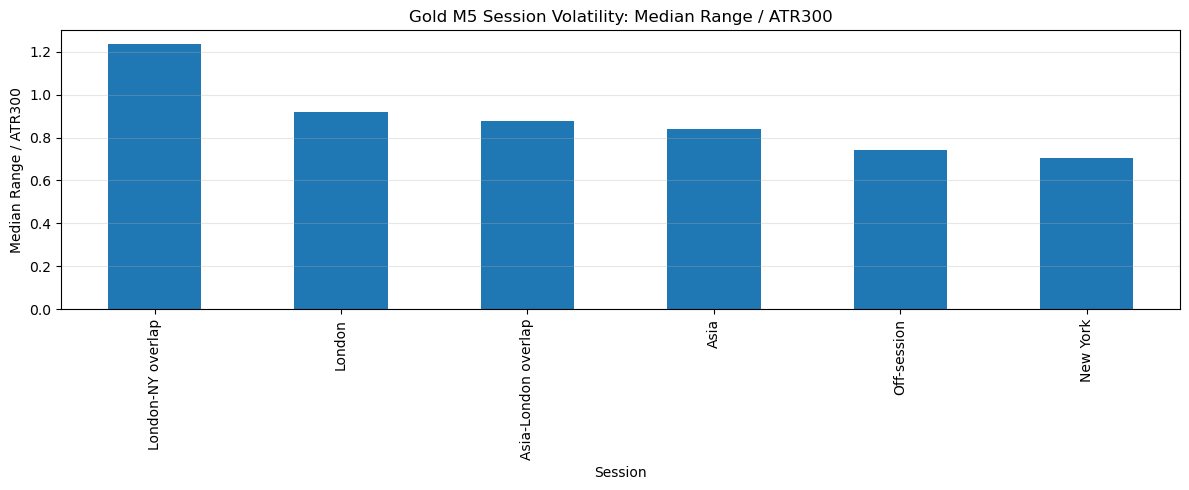

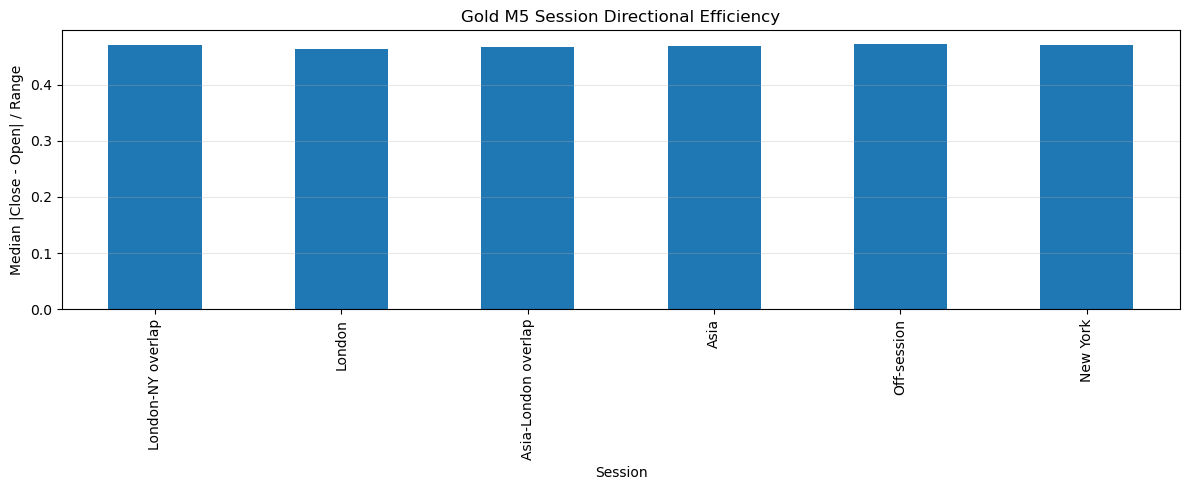

,days,median_session_range_atr300,mean_session_range_atr300,p75_session_range_atr300,p90_session_range_atr300,median_raw_range,mean_raw_range
session,,,,,,,
Asia,327,9.374489,10.231145,12.043280,15.421693,35.180,47.151957
London,327,7.623739,8.586518,10.016203,13.339174,28.930,37.276300
London-NY overlap,326,7.473462,8.484309,9.713879,12.495791,30.390,39.587914
New York,326,6.273552,7.515484,8.601796,13.022103,24.165,35.498497
Asia-London overlap,327,4.572496,5.178600,6.221111,8.307225,16.990,22.991896
Off-session,327,4.131424,5.073033,5.926795,9.278575,16.480,24.616269


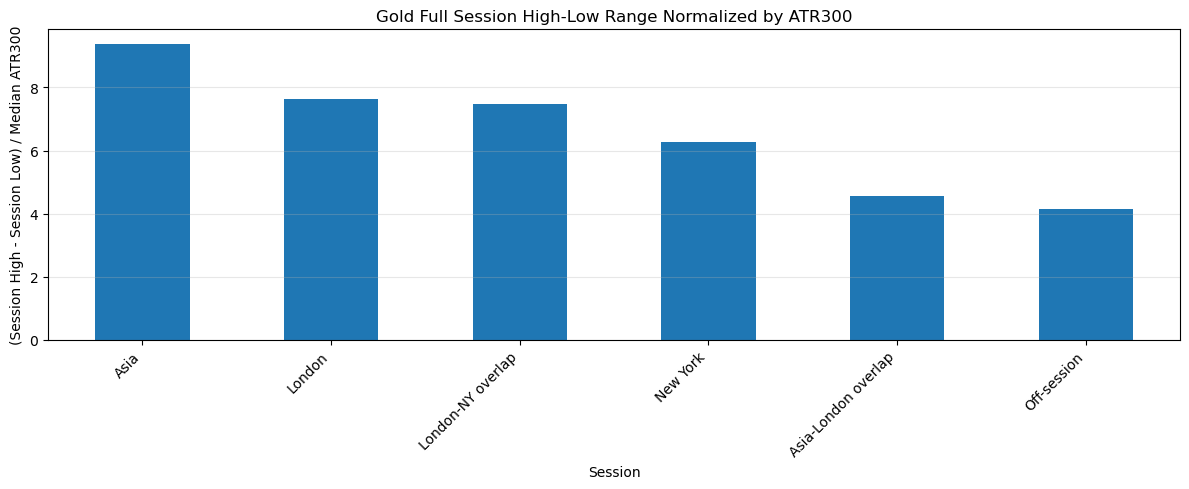

C:\Users\amirj\AppData\Local\Temp\ipykernel_6048\3103081.py:310: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


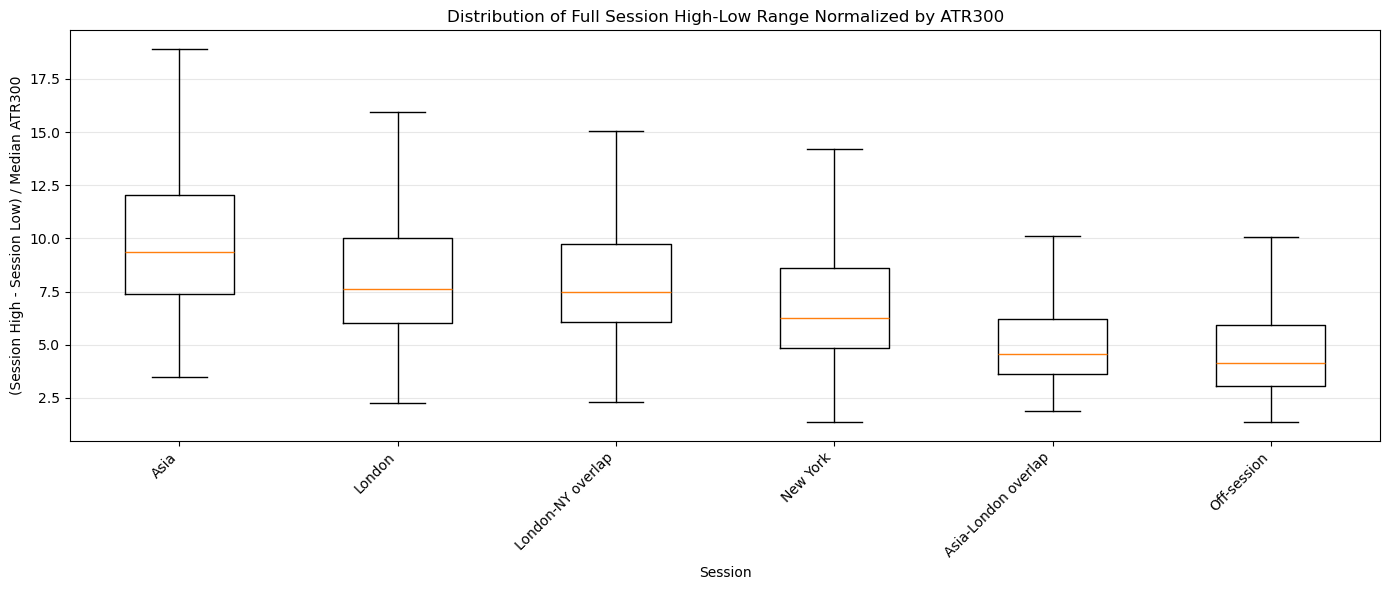

,time,open,high,low,close,tick_volume,spread,real_volume,range,body,...,range_atr14,atr300,range_atr300,minute_of_day,tod,hour,in_asia,in_london,in_ny,session
89995,2026-05-20 12:10:00+00:00,4482.19,4482.51,4479.93,4480.36,419,0,0,2.58,1.83,...,0.479618,5.891467,0.437922,730,12:10,12,False,True,False,London
89996,2026-05-20 12:15:00+00:00,4480.09,4482.60,4479.23,4482.60,419,0,0,3.37,2.51,...,0.649504,5.891533,0.572007,735,12:15,12,False,True,False,London
89997,2026-05-20 12:20:00+00:00,4482.63,4483.69,4478.91,4479.50,381,0,0,4.78,3.13,...,0.946133,5.890833,0.811430,740,12:20,12,False,True,False,London
89998,2026-05-20 12:25:00+00:00,4479.46,4479.61,4473.02,4474.29,434,0,0,6.59,5.17,...,1.263143,5.896067,1.117694,745,12:25,12,False,True,False,London
89999,2026-05-20 12:30:00+00:00,4474.20,4480.05,4473.01,4479.87,267,1,0,7.04,5.67,...,1.371556,5.901733,1.192870,750,12:30,12,False,True,False,London


In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =========================
# 1. Prepare data
# =========================

d = df.copy()

d["time"] = pd.to_datetime(d["time"])
d = d.sort_values("time").reset_index(drop=True)

# Broker time is already UTC+03:00 according to you.
# If your dataframe time is NOT broker time, shift it before this analysis.
d["broker_time"] = d["time"]

# Basic candle metrics
d["range_raw"] = d["high"] - d["low"]
d["body_raw"] = (d["close"] - d["open"]).abs()
d["direction"] = np.sign(d["close"] - d["open"])

# Avoid division errors
d.loc[d["range_raw"] <= 0, "range_raw"] = np.nan

# Directional efficiency:
# close-to-open movement as fraction of full candle range.
# Near 1 = clean directional candle.
# Near 0 = wick/chop candle.
d["directional_efficiency"] = d["body_raw"] / d["range_raw"]

# Wick/chop ratio
d["wick_ratio"] = 1 - d["directional_efficiency"]

# =========================
# 2. ATR alternatives
# =========================

# True range
prev_close = d["close"].shift(1)

tr1 = d["high"] - d["low"]
tr2 = (d["high"] - prev_close).abs()
tr3 = (d["low"] - prev_close).abs()

d["true_range"] = pd.concat([tr1, tr2, tr3], axis=1).max(axis=1)

atr_periods = [14,300]

for p in atr_periods:
    d[f"atr{p}"] = d["true_range"].rolling(p).mean()
    d[f"range_atr{p}"] = d["range_raw"] / d[f"atr{p}"]

# =========================
# 3. Broker-time sessions
# =========================

def minutes_since_midnight(ts):
    return ts.hour * 60 + ts.minute

d["minute_of_day"] = d["broker_time"].apply(minutes_since_midnight)
d["tod"] = d["broker_time"].dt.strftime("%H:%M")
d["hour"] = d["broker_time"].dt.hour

# Broker time UTC+03:00
# These are practical trading-session buckets for gold.
# Adjust if your broker has special server behavior.

ASIA_START   = 3 * 60      # 03:00 broker
ASIA_END     = 12 * 60     # 12:00 broker

LONDON_START = 10 * 60     # 10:00 broker
LONDON_END   = 19 * 60     # 19:00 broker

NY_START     = 16 * 60 + 30  # 16:30 broker, NYSE open
NY_END       = 1 * 60        # 01:00 broker next day

def in_range_wrap(m, start, end):
    if start <= end:
        return start <= m < end
    else:
        return (m >= start) or (m < end)

d["in_asia"] = d["minute_of_day"].apply(lambda m: in_range_wrap(m, ASIA_START, ASIA_END))
d["in_london"] = d["minute_of_day"].apply(lambda m: in_range_wrap(m, LONDON_START, LONDON_END))
d["in_ny"] = d["minute_of_day"].apply(lambda m: in_range_wrap(m, NY_START, NY_END))

def session_label(row):
    asia = row["in_asia"]
    london = row["in_london"]
    ny = row["in_ny"]

    if asia and london and ny:
        return "Asia + London + NY"
    elif asia and london:
        return "Asia-London overlap"
    elif london and ny:
        return "London-NY overlap"
    elif asia and ny:
        return "Asia-NY overlap"
    elif asia:
        return "Asia"
    elif london:
        return "London"
    elif ny:
        return "New York"
    else:
        return "Off-session"

d["session"] = d.apply(session_label, axis=1)

# =========================
# 4. Intraday profile by ATR choice
# =========================

profile_cols = [f"range_atr{p}" for p in atr_periods]

tod_stats = (
    d
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=profile_cols)
    .groupby("tod")[profile_cols + ["directional_efficiency", "wick_ratio"]]
    .agg(["mean", "median"])
)

tod_stats.columns = ["_".join(col) for col in tod_stats.columns]
tod_stats = tod_stats.reset_index()

# =========================
# 5. Plot ATR normalization comparison
# =========================

plt.figure(figsize=(16, 6))

x = np.arange(len(tod_stats))

for p in atr_periods:
    plt.plot(
        x,
        tod_stats[f"range_atr{p}_median"],
        label=f"Median range / ATR{p}"
    )

step = 12  # 1 hour on M5 data
plt.xticks(x[::step], tod_stats["tod"].iloc[::step], rotation=45)

plt.title("Gold M5 Intraday Range Normalized by Different ATR Lengths")
plt.xlabel("Broker Time of Day UTC+03:00")
plt.ylabel("Median Candle Range / ATR")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# =========================
# 6. Directional efficiency by time
# =========================

plt.figure(figsize=(16, 5))

plt.plot(
    x,
    tod_stats["directional_efficiency_median"],
    label="Median directional efficiency"
)

plt.xticks(x[::step], tod_stats["tod"].iloc[::step], rotation=45)

plt.title("Gold M5 Directional Efficiency by Time of Day")
plt.xlabel("Broker Time of Day UTC+03:00")
plt.ylabel("|Close - Open| / Range")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# =========================
# 7. Session-based volatility comparison
# =========================

session_stats = (
    d
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=["range_atr300", "directional_efficiency"])
    .groupby("session")
    .agg(
        candles=("range_atr300", "count"),
        median_range_atr300=("range_atr300", "median"),
        mean_range_atr300=("range_atr300", "mean"),
        p75_range_atr300=("range_atr300", lambda x: x.quantile(0.75)),
        p90_range_atr300=("range_atr300", lambda x: x.quantile(0.90)),
        median_directional_efficiency=("directional_efficiency", "median"),
        median_wick_ratio=("wick_ratio", "median"),
        median_tick_volume=("tick_volume", "median"),
        mean_tick_volume=("tick_volume", "mean"),
    )
    .sort_values("median_range_atr300", ascending=False)
)

display(session_stats)

# =========================
# 8. Bar plot: session volatility
# =========================

plt.figure(figsize=(12, 5))

session_stats["median_range_atr300"].plot(kind="bar")

plt.title("Gold M5 Session Volatility: Median Range / ATR300")
plt.xlabel("Session")
plt.ylabel("Median Range / ATR300")
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# =========================
# 9. Bar plot: session candle quality
# =========================

plt.figure(figsize=(12, 5))

session_stats["median_directional_efficiency"].plot(kind="bar")

plt.title("Gold M5 Session Directional Efficiency")
plt.xlabel("Session")
plt.ylabel("Median |Close - Open| / Range")
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# =========================
# 10. Full session high-low range normalized by ATR300
# =========================

session_range_df = d.copy()

session_range_df["date"] = session_range_df["broker_time"].dt.date

# Use median ATR300 inside each session as the volatility baseline
daily_session_ranges = (
    session_range_df
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=["atr300"])
    .groupby(["date", "session"])
    .agg(
        session_high=("high", "max"),
        session_low=("low", "min"),
        session_range=("high", lambda x: np.nan),  # placeholder
        median_atr300=("atr300", "median"),
        candles=("close", "count")
    )
    .reset_index()
)

daily_session_ranges["session_range"] = (
    daily_session_ranges["session_high"] - daily_session_ranges["session_low"]
)

daily_session_ranges["session_range_atr300"] = (
    daily_session_ranges["session_range"] / daily_session_ranges["median_atr300"]
)

# Remove tiny incomplete session fragments
daily_session_ranges = daily_session_ranges[daily_session_ranges["candles"] >= 6]

session_range_summary = (
    daily_session_ranges
    .groupby("session")
    .agg(
        days=("session_range_atr300", "count"),
        median_session_range_atr300=("session_range_atr300", "median"),
        mean_session_range_atr300=("session_range_atr300", "mean"),
        p75_session_range_atr300=("session_range_atr300", lambda x: x.quantile(0.75)),
        p90_session_range_atr300=("session_range_atr300", lambda x: x.quantile(0.90)),
        median_raw_range=("session_range", "median"),
        mean_raw_range=("session_range", "mean"),
    )
    .sort_values("median_session_range_atr300", ascending=False)
)

display(session_range_summary)

# Bar plot comparison
plt.figure(figsize=(12, 5))

session_range_summary["median_session_range_atr300"].plot(kind="bar")

plt.title("Gold Full Session High-Low Range Normalized by ATR300")
plt.xlabel("Session")
plt.ylabel("(Session High - Session Low) / Median ATR300")
plt.grid(True, axis="y", alpha=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Boxplot distribution
session_order = session_range_summary.index.tolist()

plot_data = [
    daily_session_ranges.loc[
        daily_session_ranges["session"] == s,
        "session_range_atr300"
    ].dropna()
    for s in session_order
]

plt.figure(figsize=(14, 6))

plt.boxplot(
    plot_data,
    labels=session_order,
    showfliers=False
)

plt.title("Distribution of Full Session High-Low Range Normalized by ATR300")
plt.xlabel("Session")
plt.ylabel("(Session High - Session Low) / Median ATR300")
plt.xticks(rotation=45, ha="right")
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
d.tail()

### separate overlaps

,candles,median_range_atr300,mean_range_atr300,p75_range_atr300,p90_range_atr300,median_body_atr300,median_directional_efficiency,median_wick_ratio,median_tick_volume,mean_tick_volume
session_clean,,,,,,,,,,
Asia core,27468,0.840395,0.963819,1.168770,1.591676,0.365793,0.469136,0.530864,491.0,517.562910
Asia-London overlap,7848,0.876679,0.989158,1.180103,1.566301,0.388959,0.466667,0.533333,502.0,535.881881
London core,17611,0.917535,1.069642,1.286921,1.779877,0.400018,0.463442,0.536558,542.0,567.664074
London-NY overlap,9780,1.237780,1.415518,1.720583,2.321316,0.545206,0.471278,0.528722,667.0,703.816462
New York core,19146,0.702128,0.828535,0.986512,1.372606,0.307830,0.471523,0.528477,482.0,490.946725
Off-session,7848,0.739667,0.920165,1.085223,1.611818,0.323743,0.473400,0.526600,324.0,360.659786


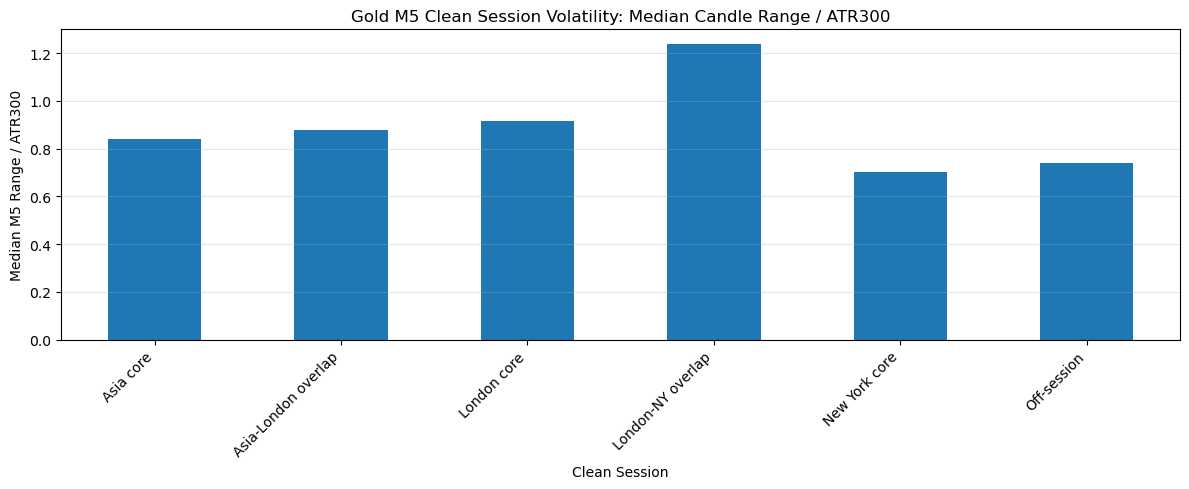

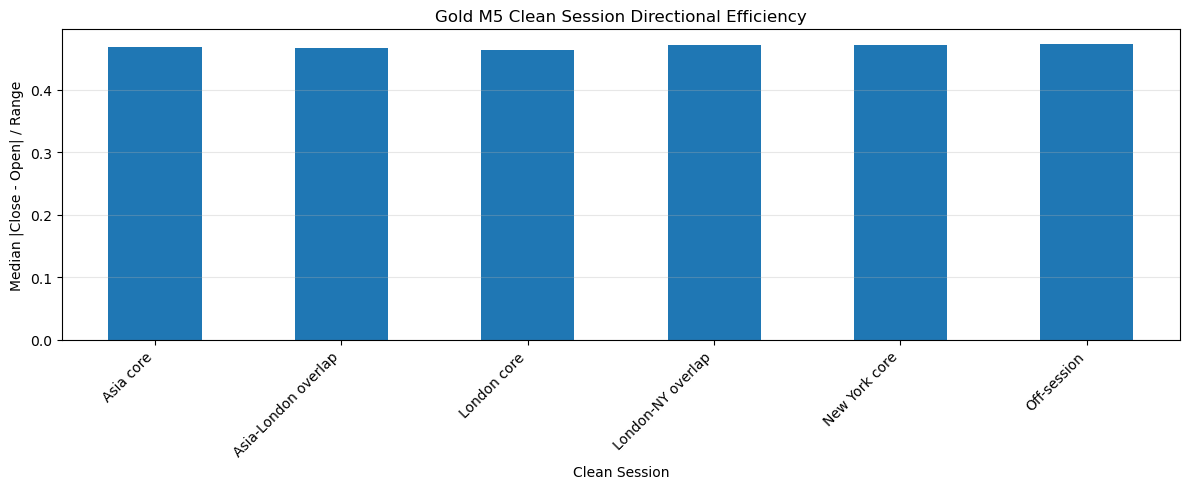

,sessions,median_session_range_atr300,mean_session_range_atr300,p75_session_range_atr300,p90_session_range_atr300,median_range_atr300_per_hour,mean_range_atr300_per_hour,median_raw_range,mean_raw_range,median_duration_hours
session_clean,,,,,,,,,,
Asia core,327,9.374489,10.231145,12.043280,15.421693,1.339213,1.461592,35.180,47.151957,7.0
Asia-London overlap,327,4.572496,5.178600,6.221111,8.307225,2.286248,2.589300,16.990,22.991896,2.0
London core,327,7.623739,8.586518,10.016203,13.339174,1.694419,1.918361,28.930,37.276300,4.5
London-NY overlap,326,7.473462,8.484309,9.713879,12.495791,2.989385,3.393724,30.390,39.587914,2.5
New York core,326,6.273552,7.515484,8.601796,13.022103,1.280190,1.537244,24.165,35.498497,5.0
Off-session,327,4.131424,5.073033,5.926795,9.278575,2.065712,2.536516,16.480,24.616269,2.0


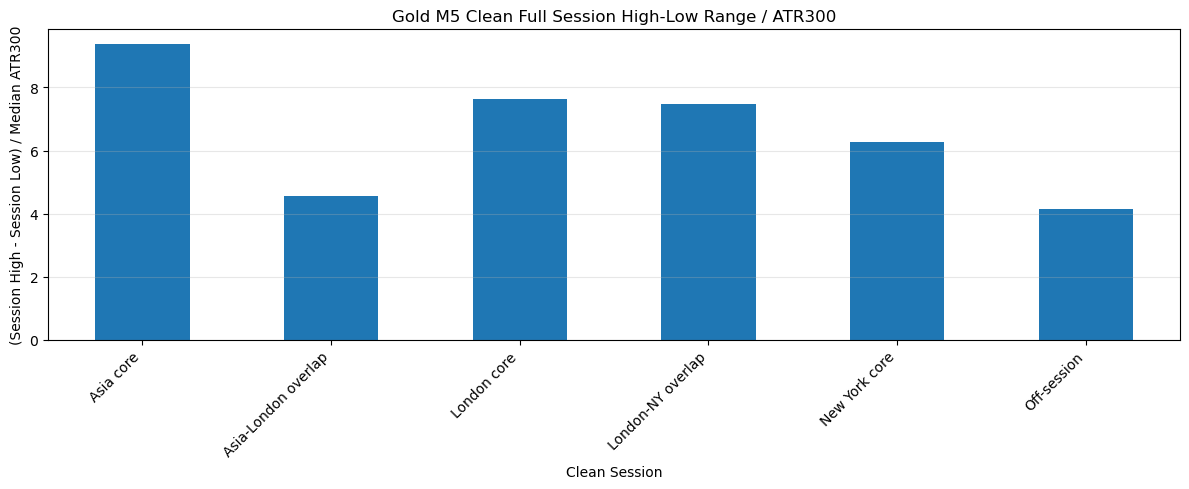

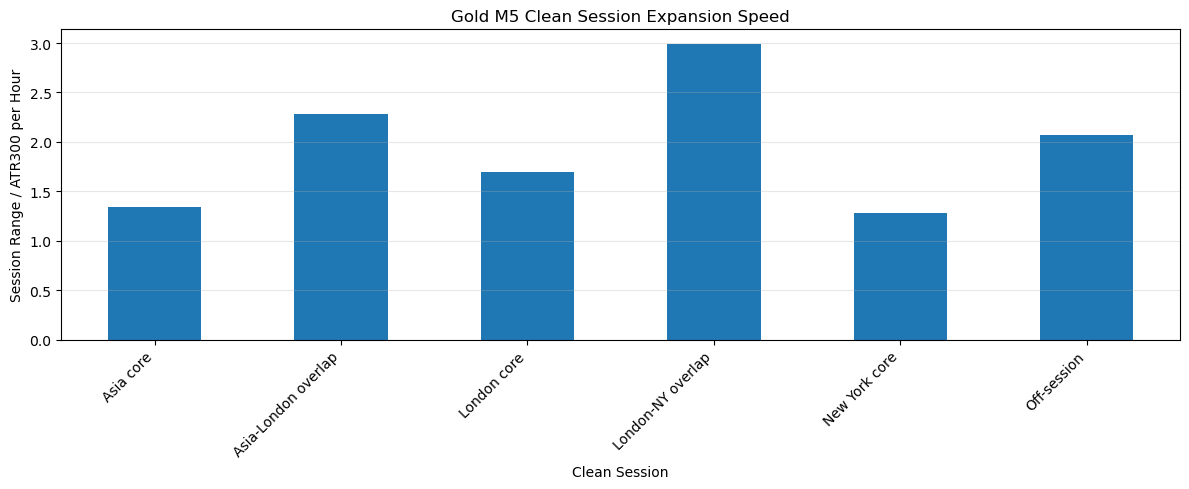

C:\Users\amirj\AppData\Local\Temp\ipykernel_6048\1432739251.py:236: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


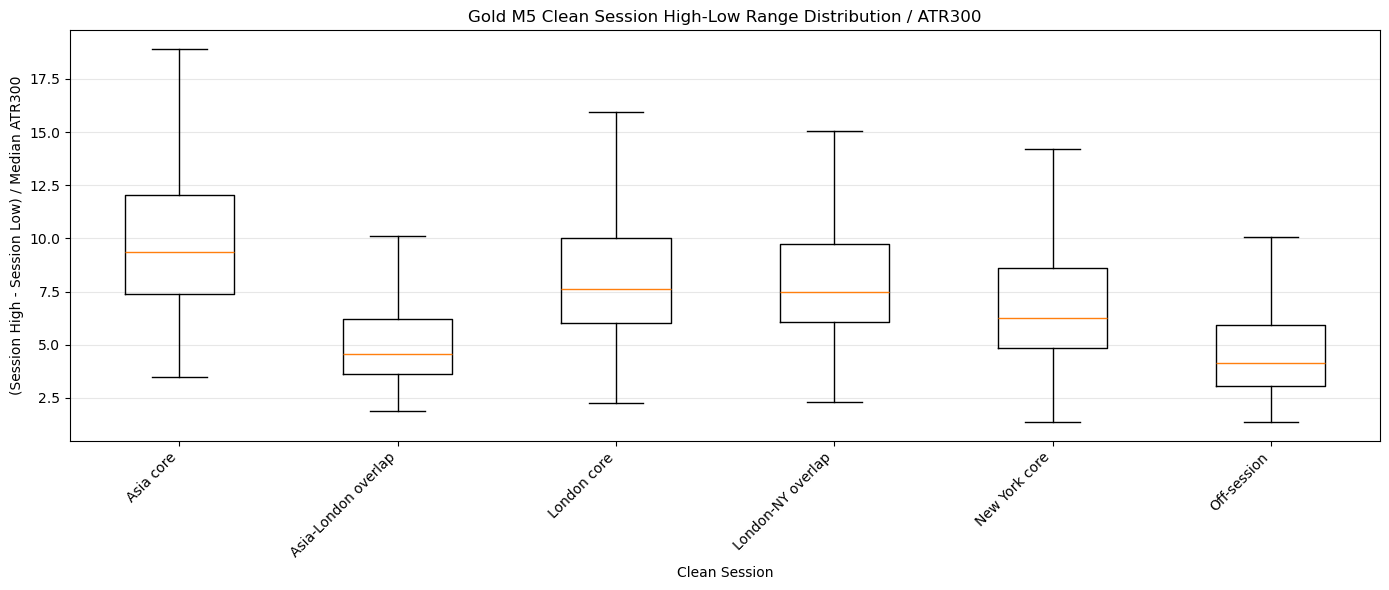

In [48]:
# =========================
# M5 Clean Non-Overlapping Session Analysis
# =========================

m5_clean = d.copy()

# Make sure broker_time exists
m5_clean["broker_time"] = pd.to_datetime(m5_clean["broker_time"])

def minutes_since_midnight(ts):
    return ts.hour * 60 + ts.minute

m5_clean["minute_of_day"] = m5_clean["broker_time"].apply(minutes_since_midnight)
m5_clean["date"] = m5_clean["broker_time"].dt.date

# Broker time UTC+03:00
# Clean non-overlapping session structure:
#
# Off-session:         01:00 - 03:00
# Asia core:           03:00 - 10:00
# Asia-London overlap: 10:00 - 12:00
# London core:         12:00 - 16:30
# London-NY overlap:   16:30 - 19:00
# New York core:       19:00 - 01:00

def clean_session_label_m5(m):
    if 3 * 60 <= m < 10 * 60:
        return "Asia core"
    elif 10 * 60 <= m < 12 * 60:
        return "Asia-London overlap"
    elif 12 * 60 <= m < 16 * 60 + 30:
        return "London core"
    elif 16 * 60 + 30 <= m < 19 * 60:
        return "London-NY overlap"
    elif m >= 19 * 60 or m < 1 * 60:
        return "New York core"
    else:
        return "Off-session"

m5_clean["session_clean"] = m5_clean["minute_of_day"].apply(clean_session_label_m5)

session_order_clean = [
    "Asia core",
    "Asia-London overlap",
    "London core",
    "London-NY overlap",
    "New York core",
    "Off-session"
]

m5_clean["session_clean"] = pd.Categorical(
    m5_clean["session_clean"],
    categories=session_order_clean,
    ordered=True
)

# =========================
# 1. Candle-level volatility by clean session
# =========================

m5_clean_session_stats = (
    m5_clean
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=["range_atr300", "directional_efficiency"])
    .groupby("session_clean", observed=False)
    .agg(
        candles=("range_atr300", "count"),

        median_range_atr300=("range_atr300", "median"),
        mean_range_atr300=("range_atr300", "mean"),
        p75_range_atr300=("range_atr300", lambda x: x.quantile(0.75)),
        p90_range_atr300=("range_atr300", lambda x: x.quantile(0.90)),

        median_body_atr300=("body_raw", lambda x: np.nan),
        median_directional_efficiency=("directional_efficiency", "median"),
        median_wick_ratio=("wick_ratio", "median"),

        median_tick_volume=("tick_volume", "median"),
        mean_tick_volume=("tick_volume", "mean"),
    )
)

# Fix body / ATR300 after groupby
m5_clean["body_atr300"] = m5_clean["body_raw"] / m5_clean["atr300"]

m5_clean_session_stats = (
    m5_clean
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=["range_atr300", "body_atr300", "directional_efficiency"])
    .groupby("session_clean", observed=False)
    .agg(
        candles=("range_atr300", "count"),

        median_range_atr300=("range_atr300", "median"),
        mean_range_atr300=("range_atr300", "mean"),
        p75_range_atr300=("range_atr300", lambda x: x.quantile(0.75)),
        p90_range_atr300=("range_atr300", lambda x: x.quantile(0.90)),

        median_body_atr300=("body_atr300", "median"),
        median_directional_efficiency=("directional_efficiency", "median"),
        median_wick_ratio=("wick_ratio", "median"),

        median_tick_volume=("tick_volume", "median"),
        mean_tick_volume=("tick_volume", "mean"),
    )
)

display(m5_clean_session_stats)

# Bar plot: clean session candle-level volatility
plt.figure(figsize=(12, 5))

m5_clean_session_stats["median_range_atr300"].plot(kind="bar")

plt.title("Gold M5 Clean Session Volatility: Median Candle Range / ATR300")
plt.xlabel("Clean Session")
plt.ylabel("Median M5 Range / ATR300")
plt.grid(True, axis="y", alpha=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Bar plot: clean session directional efficiency
plt.figure(figsize=(12, 5))

m5_clean_session_stats["median_directional_efficiency"].plot(kind="bar")

plt.title("Gold M5 Clean Session Directional Efficiency")
plt.xlabel("Clean Session")
plt.ylabel("Median |Close - Open| / Range")
plt.grid(True, axis="y", alpha=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# =========================
# 2. Full clean session high-low range normalized by ATR300
# =========================

m5_clean_session_ranges = (
    m5_clean
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=["atr300"])
    .groupby(["date", "session_clean"], observed=False)
    .agg(
        session_high=("high", "max"),
        session_low=("low", "min"),
        median_atr300=("atr300", "median"),
        candles=("close", "count")
    )
    .reset_index()
)

m5_clean_session_ranges["session_range"] = (
    m5_clean_session_ranges["session_high"] - m5_clean_session_ranges["session_low"]
)

m5_clean_session_ranges["session_range_atr300"] = (
    m5_clean_session_ranges["session_range"] / m5_clean_session_ranges["median_atr300"]
)

# Minimum 6 M5 candles = 30 minutes
m5_clean_session_ranges = m5_clean_session_ranges[
    m5_clean_session_ranges["candles"] >= 6
].copy()

# Duration-adjusted metric
m5_clean_session_ranges["duration_hours"] = (
    m5_clean_session_ranges["candles"] * 5 / 60
)

m5_clean_session_ranges["session_range_atr300_per_hour"] = (
    m5_clean_session_ranges["session_range_atr300"]
    / m5_clean_session_ranges["duration_hours"]
)

m5_clean_session_range_summary = (
    m5_clean_session_ranges
    .groupby("session_clean", observed=False)
    .agg(
        sessions=("session_range_atr300", "count"),

        median_session_range_atr300=("session_range_atr300", "median"),
        mean_session_range_atr300=("session_range_atr300", "mean"),
        p75_session_range_atr300=("session_range_atr300", lambda x: x.quantile(0.75)),
        p90_session_range_atr300=("session_range_atr300", lambda x: x.quantile(0.90)),

        median_range_atr300_per_hour=("session_range_atr300_per_hour", "median"),
        mean_range_atr300_per_hour=("session_range_atr300_per_hour", "mean"),

        median_raw_range=("session_range", "median"),
        mean_raw_range=("session_range", "mean"),
        median_duration_hours=("duration_hours", "median"),
    )
)

display(m5_clean_session_range_summary)

# Bar plot: full session high-low range
plt.figure(figsize=(12, 5))

m5_clean_session_range_summary["median_session_range_atr300"].plot(kind="bar")

plt.title("Gold M5 Clean Full Session High-Low Range / ATR300")
plt.xlabel("Clean Session")
plt.ylabel("(Session High - Session Low) / Median ATR300")
plt.grid(True, axis="y", alpha=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Bar plot: duration-adjusted session expansion
plt.figure(figsize=(12, 5))

m5_clean_session_range_summary["median_range_atr300_per_hour"].plot(kind="bar")

plt.title("Gold M5 Clean Session Expansion Speed")
plt.xlabel("Clean Session")
plt.ylabel("Session Range / ATR300 per Hour")
plt.grid(True, axis="y", alpha=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Boxplot: full clean session range distribution
m5_plot_data = [
    m5_clean_session_ranges.loc[
        m5_clean_session_ranges["session_clean"] == s,
        "session_range_atr300"
    ].dropna()
    for s in session_order_clean
]

plt.figure(figsize=(14, 6))

plt.boxplot(
    m5_plot_data,
    labels=session_order_clean,
    showfliers=False
)

plt.title("Gold M5 Clean Session High-Low Range Distribution / ATR300")
plt.xlabel("Clean Session")
plt.ylabel("(Session High - Session Low) / Median ATR300")
plt.grid(True, axis="y", alpha=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Daily chart

,candles,median_range_raw,mean_range_raw,p75_range_raw,p90_range_raw,median_range_atr14,median_range_atr20,median_range_atr60,median_range_atr250,mean_range_atr250,p75_range_atr250,p90_range_atr250,median_body_atr250,median_directional_efficiency,median_wick_ratio
month_name,,,,,,,,,,,,,,,
January,320,19.175,29.082062,27.5550,39.319,0.947544,0.937358,0.896615,0.879248,1.033105,1.189309,1.523894,0.350205,0.448269,0.551731
February,303,19.440,32.440594,30.2800,54.750,0.930879,0.933010,0.969177,0.926604,1.121376,1.278684,1.842463,0.395390,0.427566,0.572434
March,327,21.930,36.318349,37.8100,63.054,0.923018,0.921084,0.971570,1.023501,1.256033,1.500060,2.126736,0.437222,0.467405,0.532595
April,311,21.500,33.132669,35.9750,81.800,0.896845,0.897321,0.873865,0.977843,1.184979,1.393714,1.903421,0.413077,0.459511,0.540489
May,326,21.110,28.191380,32.5225,52.540,0.911980,0.901338,0.862334,0.930627,1.037758,1.261673,1.688267,0.353485,0.403755,0.596245
June,292,18.750,23.190788,28.1650,42.648,0.897220,0.900445,0.834501,0.862840,0.995339,1.159654,1.635752,0.351232,0.443353,0.556647
July,308,19.060,22.102857,27.4400,39.489,0.960672,0.948428,0.861024,0.883792,0.975809,1.224671,1.552248,0.341004,0.425033,0.574967
August,308,18.340,22.715747,27.6300,40.852,0.877644,0.876741,0.859299,0.833154,1.003854,1.176005,1.725900,0.340564,0.415768,0.584232
September,293,18.910,23.051092,28.5900,43.576,0.974195,0.952765,0.943006,0.922985,0.978700,1.176063,1.521421,0.364390,0.437805,0.562195


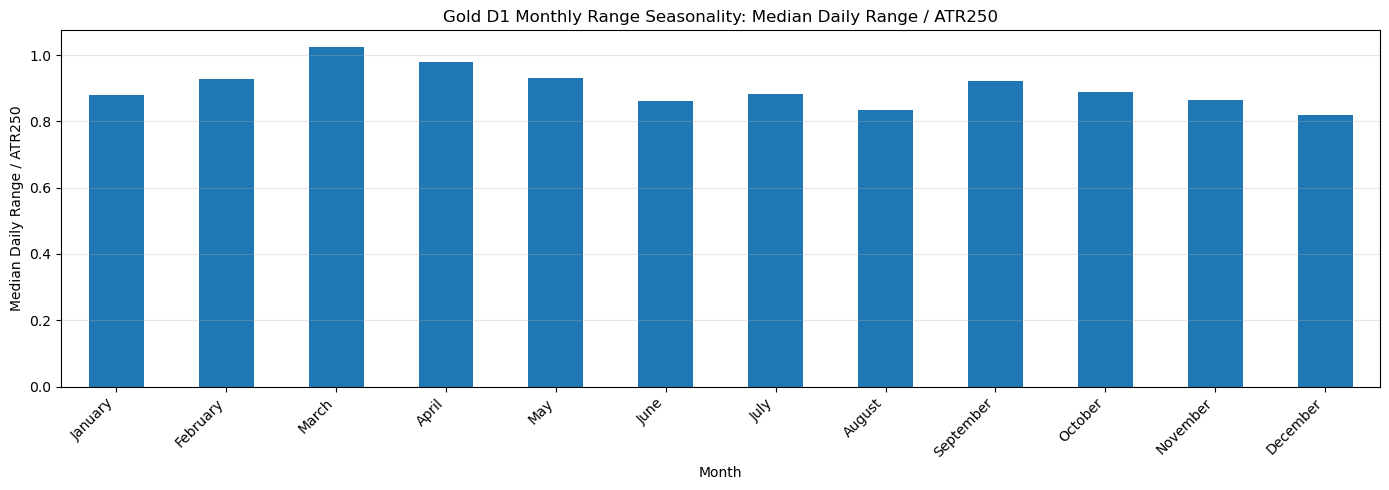

C:\Users\amirj\AppData\Local\Temp\ipykernel_6048\2461946515.py:146: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


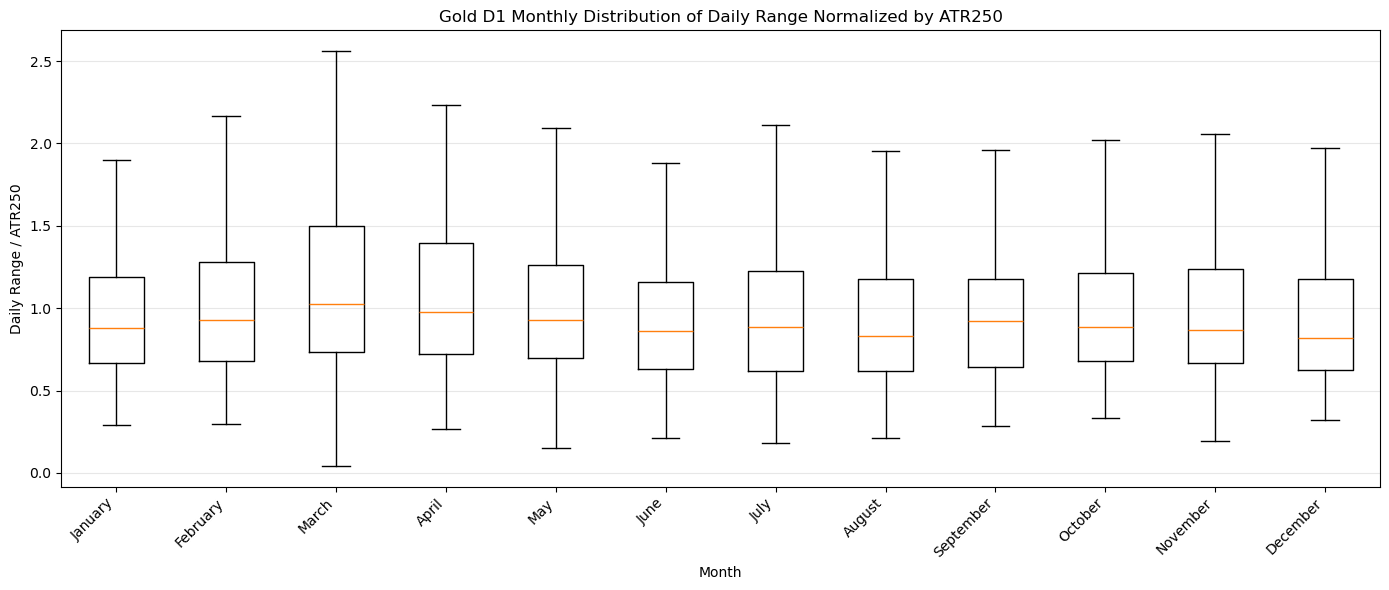

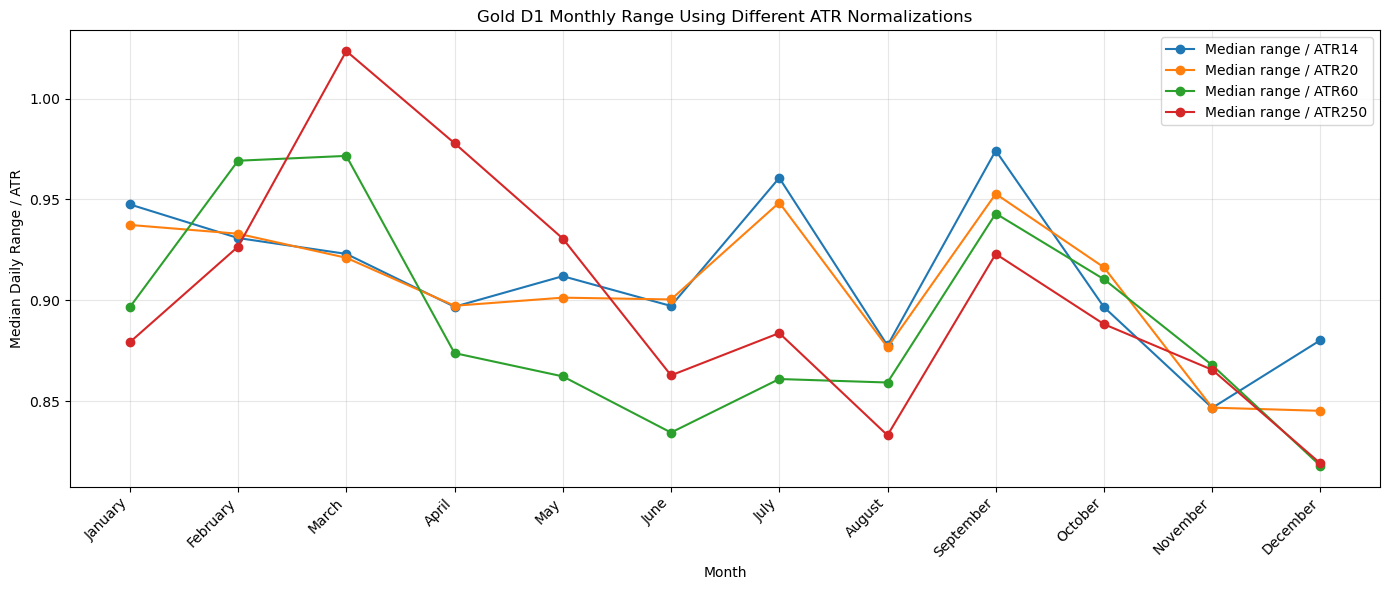

,candles,median_range_raw,mean_range_raw,p75_range_raw,p90_range_raw,median_range_atr14,median_range_atr20,median_range_atr60,median_range_atr250,mean_range_atr250,p75_range_atr250,p90_range_atr250,median_body_atr250,median_directional_efficiency,median_wick_ratio
weekday,,,,,,,,,,,,,,,
Monday,741,17.180,26.600850,27.0200,48.850,0.831876,0.819277,0.817245,0.822900,0.999855,1.153803,1.718104,0.324439,0.425446,0.574554
Tuesday,744,19.335,26.892231,29.1200,46.127,0.905949,0.891995,0.878880,0.884226,1.030124,1.232715,1.598601,0.383040,0.445051,0.554949
Wednesday,742,19.865,26.529838,29.1950,46.311,0.916947,0.907037,0.882657,0.895891,1.044410,1.251566,1.715893,0.376203,0.446619,0.553381
Thursday,742,20.270,27.737884,30.9150,46.908,0.946945,0.932144,0.916416,0.929936,1.075230,1.271980,1.755509,0.384261,0.440512,0.559488
Friday,726,20.725,28.678223,31.4625,50.435,0.961869,0.962045,0.936240,0.957640,1.108491,1.318276,1.803726,0.409091,0.448859,0.551141


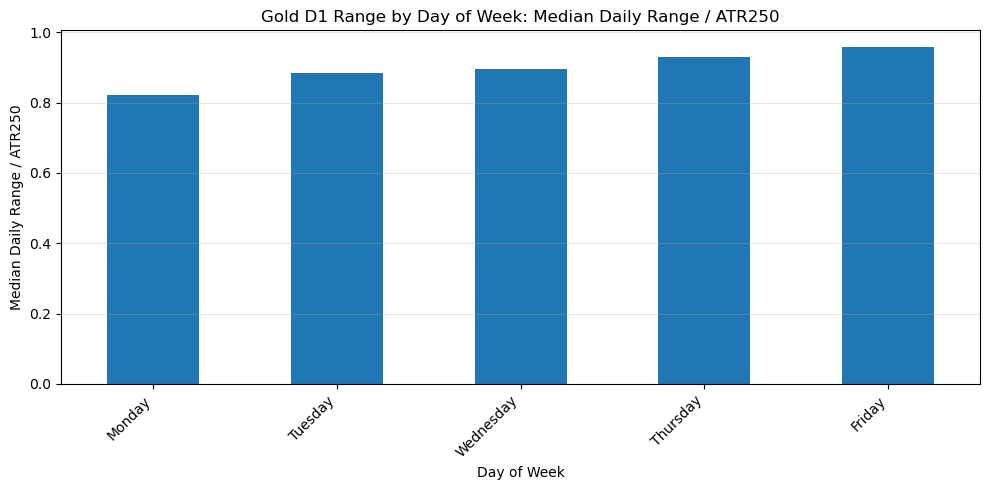

C:\Users\amirj\AppData\Local\Temp\ipykernel_6048\2461946515.py:244: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


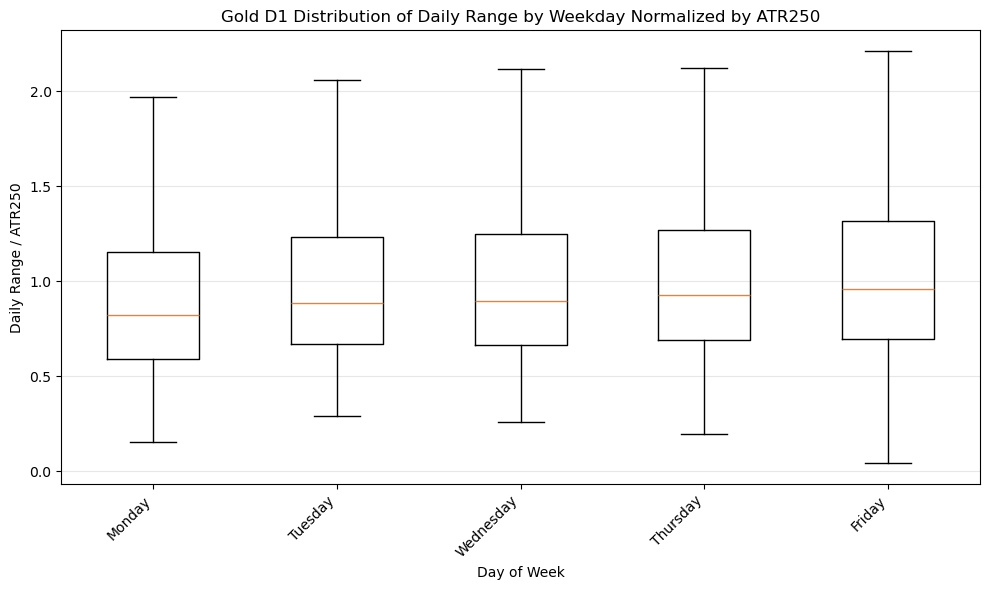

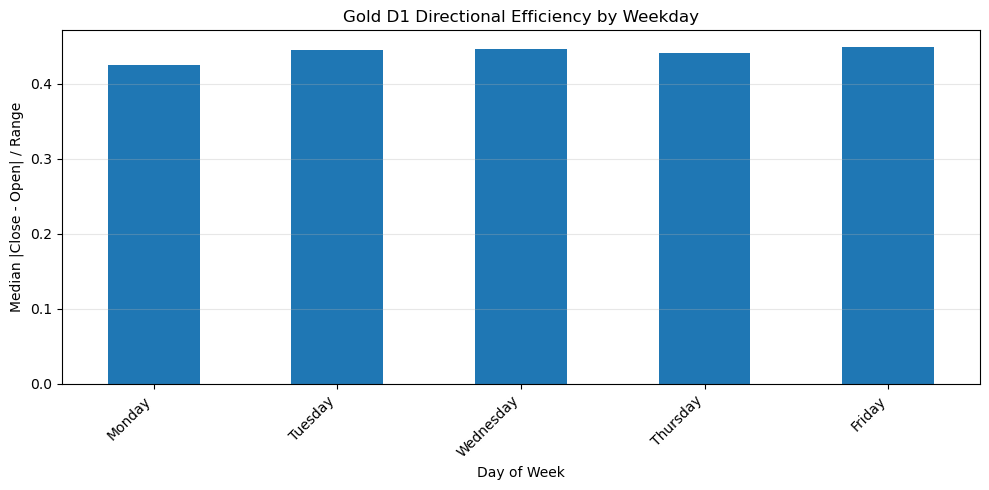

In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =========================
# Gold D1 Monthly & Weekday Range Analyzer
# =========================

# 1. Load D1 data
d1_path = r"mt5_data\XAUUSDzero_D1_max_bars.csv"

d1 = pd.read_csv(d1_path)

# 2. Prepare data
d1["time"] = pd.to_datetime(d1["time"])
d1 = d1.sort_values("time").reset_index(drop=True)

# Basic daily candle metrics
d1["range_raw"] = d1["high"] - d1["low"]
d1["body_raw"] = (d1["close"] - d1["open"]).abs()

# Avoid division issues
d1.loc[d1["range_raw"] <= 0, "range_raw"] = np.nan

# Directional efficiency
d1["directional_efficiency"] = d1["body_raw"] / d1["range_raw"]
d1["wick_ratio"] = 1 - d1["directional_efficiency"]

# =========================
# 3. Daily ATR calculations
# =========================

prev_close = d1["close"].shift(1)

tr1 = d1["high"] - d1["low"]
tr2 = (d1["high"] - prev_close).abs()
tr3 = (d1["low"] - prev_close).abs()

d1["true_range"] = pd.concat([tr1, tr2, tr3], axis=1).max(axis=1)

# For D1:
# ATR14 = short-term daily volatility
# ATR20 = about one trading month
# ATR60 = about one quarter
# ATR250 = about one trading year
atr_periods = [14, 20, 60, 250]

for p in atr_periods:
    d1[f"atr{p}"] = d1["true_range"].rolling(p).mean()
    d1[f"range_atr{p}"] = d1["range_raw"] / d1[f"atr{p}"]
    d1[f"body_atr{p}"] = d1["body_raw"] / d1[f"atr{p}"]

# =========================
# 4. Time labels
# =========================

d1["month"] = d1["time"].dt.month
d1["month_name"] = d1["time"].dt.month_name()
d1["weekday"] = d1["time"].dt.day_name()

month_order = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"
]

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday", "Friday"
]

d1["month_name"] = pd.Categorical(
    d1["month_name"],
    categories=month_order,
    ordered=True
)

d1["weekday"] = pd.Categorical(
    d1["weekday"],
    categories=weekday_order,
    ordered=True
)

# Remove weekends if they exist in broker data
d1 = d1[d1["weekday"].notna()].copy()

# =========================
# 5. Monthly D1 range analysis
# =========================

month_stats = (
    d1
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=["range_atr250"])
    .groupby("month_name", observed=False)
    .agg(
        candles=("range_atr250", "count"),

        median_range_raw=("range_raw", "median"),
        mean_range_raw=("range_raw", "mean"),
        p75_range_raw=("range_raw", lambda x: x.quantile(0.75)),
        p90_range_raw=("range_raw", lambda x: x.quantile(0.90)),

        median_range_atr14=("range_atr14", "median"),
        median_range_atr20=("range_atr20", "median"),
        median_range_atr60=("range_atr60", "median"),
        median_range_atr250=("range_atr250", "median"),

        mean_range_atr250=("range_atr250", "mean"),
        p75_range_atr250=("range_atr250", lambda x: x.quantile(0.75)),
        p90_range_atr250=("range_atr250", lambda x: x.quantile(0.90)),

        median_body_atr250=("body_atr250", "median"),
        median_directional_efficiency=("directional_efficiency", "median"),
        median_wick_ratio=("wick_ratio", "median"),
    )
)

display(month_stats)

# =========================
# 6. Plot monthly normalized daily range
# =========================

plt.figure(figsize=(14, 5))

month_stats["median_range_atr250"].plot(kind="bar")

plt.title("Gold D1 Monthly Range Seasonality: Median Daily Range / ATR250")
plt.xlabel("Month")
plt.ylabel("Median Daily Range / ATR250")
plt.grid(True, axis="y", alpha=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# =========================
# 7. Monthly distribution boxplot
# =========================

month_plot_data = [
    d1.loc[d1["month_name"] == m, "range_atr250"].dropna()
    for m in month_order
]

plt.figure(figsize=(14, 6))

plt.boxplot(
    month_plot_data,
    labels=month_order,
    showfliers=False
)

plt.title("Gold D1 Monthly Distribution of Daily Range Normalized by ATR250")
plt.xlabel("Month")
plt.ylabel("Daily Range / ATR250")
plt.grid(True, axis="y", alpha=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# =========================
# 8. Compare ATR normalizations by month
# =========================

plt.figure(figsize=(14, 6))

for p in atr_periods:
    plt.plot(
        month_stats.index.astype(str),
        month_stats[f"median_range_atr{p}"],
        marker="o",
        label=f"Median range / ATR{p}"
    )

plt.title("Gold D1 Monthly Range Using Different ATR Normalizations")
plt.xlabel("Month")
plt.ylabel("Median Daily Range / ATR")
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

# =========================
# 9. Weekday D1 range analysis
# =========================

weekday_stats = (
    d1
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=["range_atr250"])
    .groupby("weekday", observed=False)
    .agg(
        candles=("range_atr250", "count"),

        median_range_raw=("range_raw", "median"),
        mean_range_raw=("range_raw", "mean"),
        p75_range_raw=("range_raw", lambda x: x.quantile(0.75)),
        p90_range_raw=("range_raw", lambda x: x.quantile(0.90)),

        median_range_atr14=("range_atr14", "median"),
        median_range_atr20=("range_atr20", "median"),
        median_range_atr60=("range_atr60", "median"),
        median_range_atr250=("range_atr250", "median"),

        mean_range_atr250=("range_atr250", "mean"),
        p75_range_atr250=("range_atr250", lambda x: x.quantile(0.75)),
        p90_range_atr250=("range_atr250", lambda x: x.quantile(0.90)),

        median_body_atr250=("body_atr250", "median"),
        median_directional_efficiency=("directional_efficiency", "median"),
        median_wick_ratio=("wick_ratio", "median"),
    )
)

display(weekday_stats)

# =========================
# 10. Plot weekday normalized daily range
# =========================

plt.figure(figsize=(10, 5))

weekday_stats["median_range_atr250"].plot(kind="bar")

plt.title("Gold D1 Range by Day of Week: Median Daily Range / ATR250")
plt.xlabel("Day of Week")
plt.ylabel("Median Daily Range / ATR250")
plt.grid(True, axis="y", alpha=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# =========================
# 11. Weekday distribution boxplot
# =========================

weekday_plot_data = [
    d1.loc[d1["weekday"] == w, "range_atr250"].dropna()
    for w in weekday_order
]

plt.figure(figsize=(10, 6))

plt.boxplot(
    weekday_plot_data,
    labels=weekday_order,
    showfliers=False
)

plt.title("Gold D1 Distribution of Daily Range by Weekday Normalized by ATR250")
plt.xlabel("Day of Week")
plt.ylabel("Daily Range / ATR250")
plt.grid(True, axis="y", alpha=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# =========================
# 12. Weekday directional efficiency
# =========================

plt.figure(figsize=(10, 5))

weekday_stats["median_directional_efficiency"].plot(kind="bar")

plt.title("Gold D1 Directional Efficiency by Weekday")
plt.xlabel("Day of Week")
plt.ylabel("Median |Close - Open| / Range")
plt.grid(True, axis="y", alpha=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## M1 chart

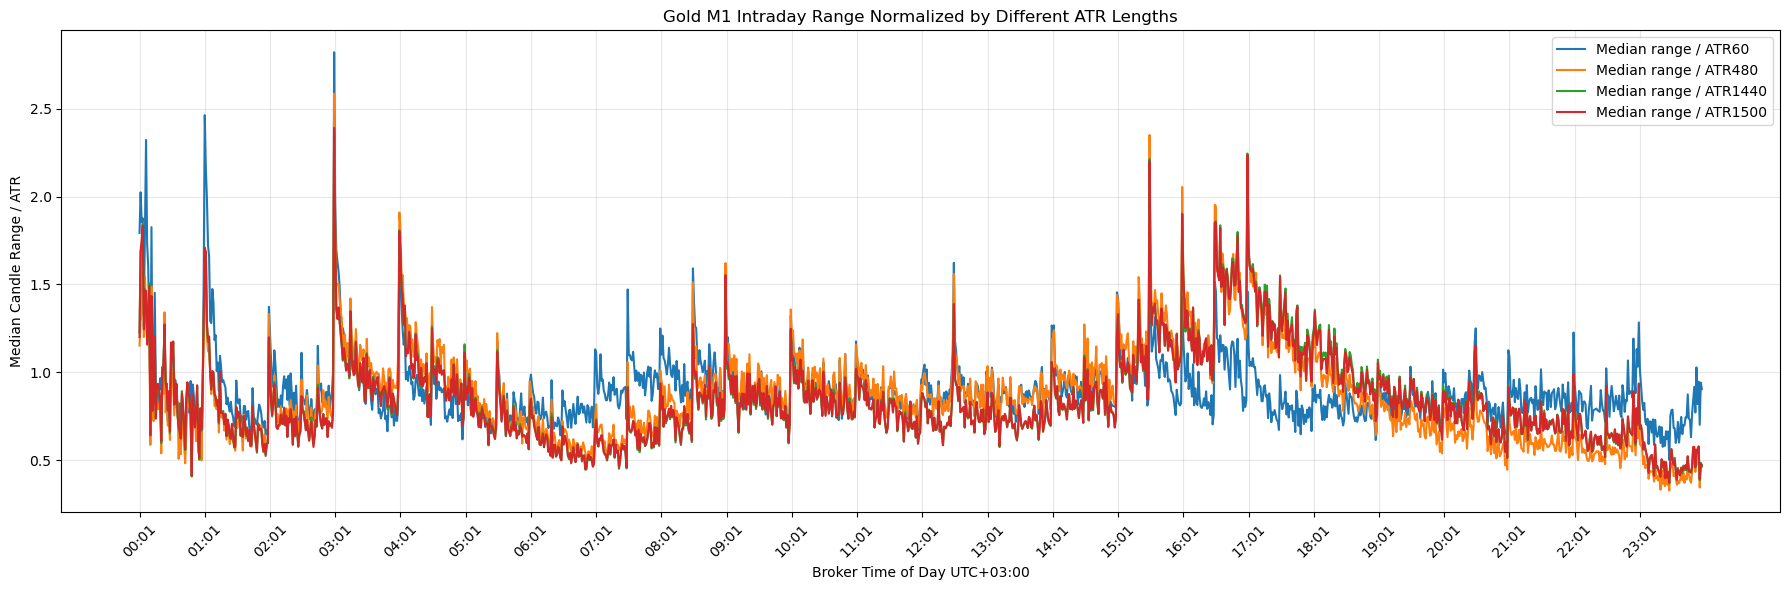

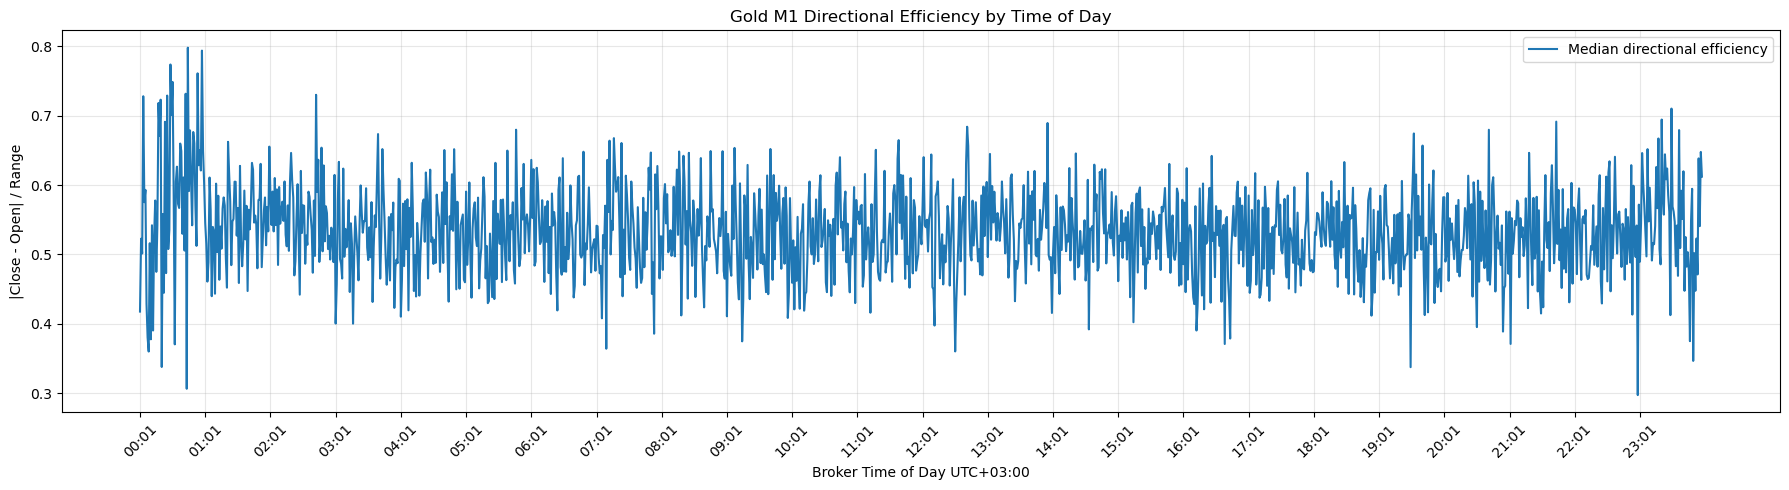

,candles,median_range_atr1500,mean_range_atr1500,p75_range_atr1500,p90_range_atr1500,median_body_atr1500,median_directional_efficiency,median_wick_ratio,median_tick_volume,mean_tick_volume
session,,,,,,,,,,
London-NY overlap,9600,1.205304,1.393768,1.691033,2.353649,0.580945,0.521406,0.478594,117.0,116.894792
London,17315,0.890038,1.074007,1.297567,1.888820,0.433068,0.531915,0.468085,92.0,93.633786
Asia-London overlap,7800,0.825467,0.942637,1.148445,1.563233,0.397520,0.529068,0.470932,88.0,88.959872
Asia,27084,0.781749,0.932688,1.148281,1.637173,0.375113,0.532731,0.467269,85.0,84.773667
Off-session,7638,0.739669,0.963124,1.159792,1.814994,0.365414,0.552433,0.447567,63.0,67.700183
New York,19063,0.708117,0.851077,1.031351,1.473342,0.341827,0.528926,0.471074,90.0,88.656927


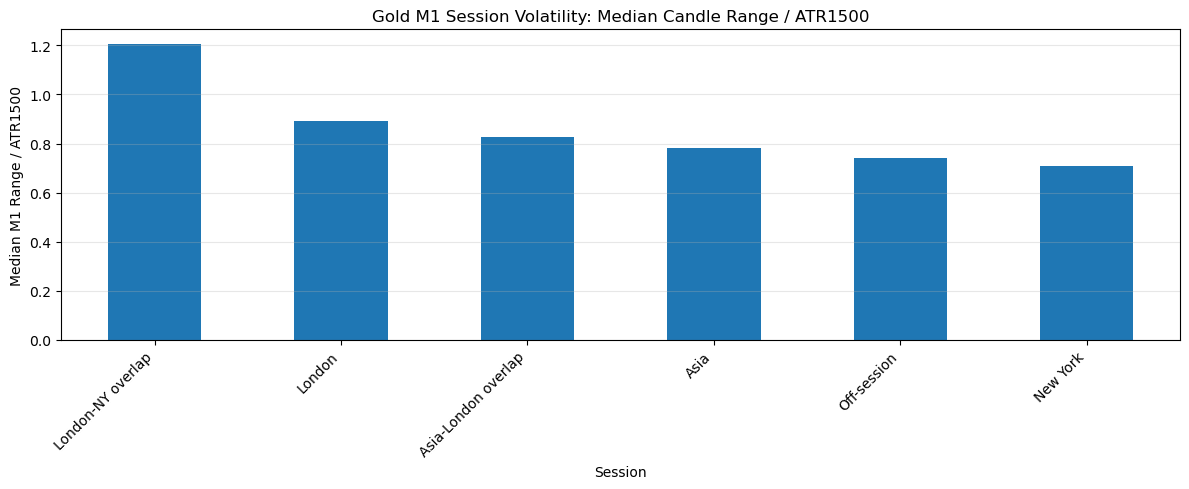

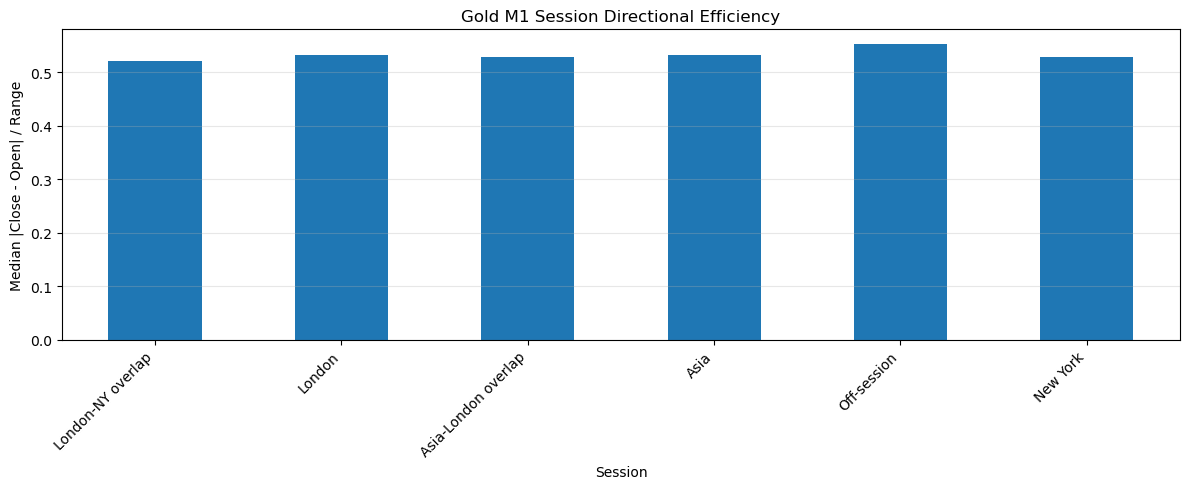

,days,median_session_range_atr1500,mean_session_range_atr1500,p75_session_range_atr1500,p90_session_range_atr1500,median_raw_range,mean_raw_range,median_candles
session,,,,,,,,
Asia,65,22.400277,24.809154,29.306004,38.854555,60.16,71.916615,420.0
London-NY overlap,64,17.723055,18.742096,22.013702,26.551182,50.53,55.899531,150.0
London,65,17.150218,21.158943,24.323332,33.660130,46.66,61.638154,270.0
New York,64,15.379645,20.618664,22.601922,39.155613,43.20,62.289375,299.0
Off-session,64,10.020485,12.510942,13.875890,25.387699,27.55,37.688594,119.0
Asia-London overlap,65,9.849968,10.909755,13.196044,15.957543,27.09,31.563231,120.0


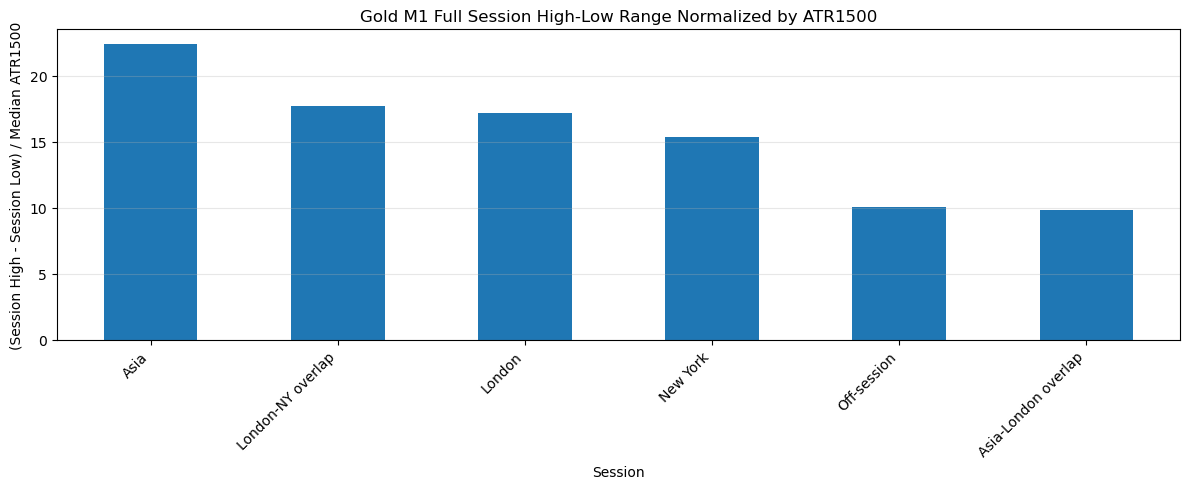

C:\Users\amirj\AppData\Local\Temp\ipykernel_6048\285279179.py:324: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


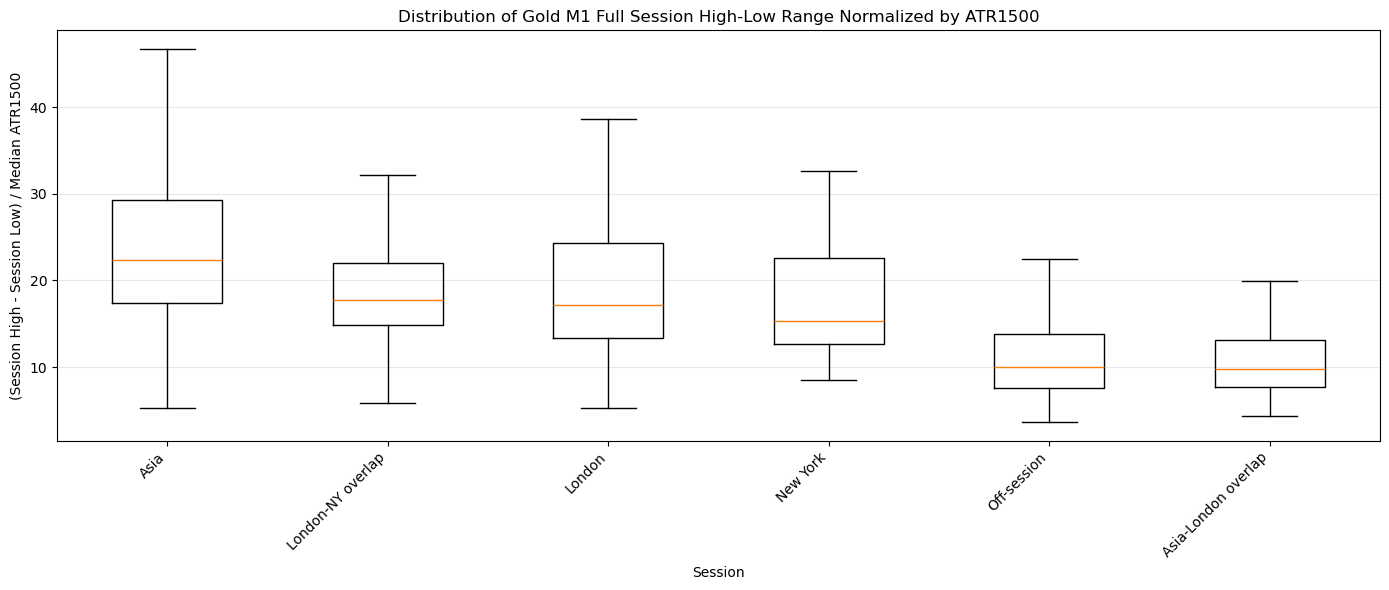

,candles,median_expansion_efficiency,p75_expansion_efficiency,p90_expansion_efficiency
session,,,,
London-NY overlap,9600,0.306400,0.743341,1.336051
London,17315,0.233941,0.573791,1.036090
Asia-London overlap,7800,0.214397,0.527444,0.908199
Off-session,7638,0.203750,0.495881,0.945461
Asia,27084,0.203649,0.502604,0.905286
New York,19063,0.183171,0.455164,0.823230


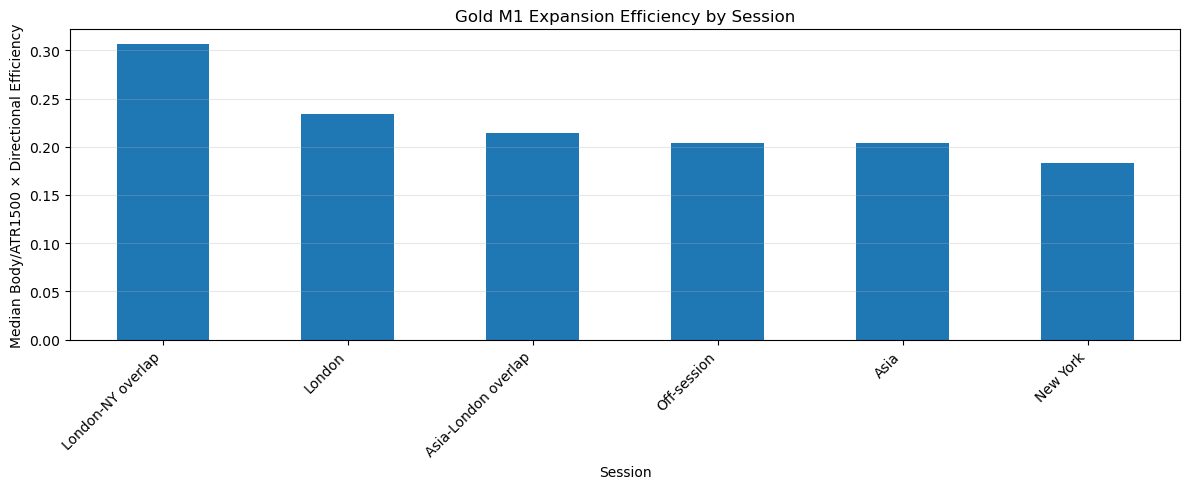

In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =========================
# Gold M1 Session Volatility & Candle Quality Analyzer
# =========================

# 1. Load M1 data
m1_path = r"mt5_data\XAUUSDzero_M1_max_bars.csv"

m1 = pd.read_csv(m1_path)

# =========================
# 2. Prepare data
# =========================

d = m1.copy()

d["time"] = pd.to_datetime(d["time"])
d = d.sort_values("time").reset_index(drop=True)

# Broker time is already UTC+03:00 according to you.
# If your dataframe time is NOT broker time, shift it before this analysis.
d["broker_time"] = d["time"]

# Basic candle metrics
d["range_raw"] = d["high"] - d["low"]
d["body_raw"] = (d["close"] - d["open"]).abs()

d.loc[d["range_raw"] <= 0, "range_raw"] = np.nan

# Candle quality
d["directional_efficiency"] = d["body_raw"] / d["range_raw"]
d["wick_ratio"] = 1 - d["directional_efficiency"]

# =========================
# 3. ATR alternatives for M1
# =========================

prev_close = d["close"].shift(1)

tr1 = d["high"] - d["low"]
tr2 = (d["high"] - prev_close).abs()
tr3 = (d["low"] - prev_close).abs()

d["true_range"] = pd.concat([tr1, tr2, tr3], axis=1).max(axis=1)

# M1 ATR periods
# ATR60   = 1 hour
# ATR480  = 8 hours
# ATR1440 = 1 day
# ATR1500 = close equivalent to M5 ATR300
atr_periods = [60, 480, 1440, 1500]

for p in atr_periods:
    d[f"atr{p}"] = d["true_range"].rolling(p).mean()
    d[f"range_atr{p}"] = d["range_raw"] / d[f"atr{p}"]
    d[f"body_atr{p}"] = d["body_raw"] / d[f"atr{p}"]

# =========================
# 4. Broker-time sessions
# =========================

def minutes_since_midnight(ts):
    return ts.hour * 60 + ts.minute

d["minute_of_day"] = d["broker_time"].apply(minutes_since_midnight)
d["tod"] = d["broker_time"].dt.strftime("%H:%M")
d["hour"] = d["broker_time"].dt.hour
d["date"] = d["broker_time"].dt.date

# Broker time UTC+03:00
# NYSE open = 16:30 broker time

ASIA_START   = 3 * 60
ASIA_END     = 12 * 60

LONDON_START = 10 * 60
LONDON_END   = 19 * 60

NY_START     = 16 * 60 + 30
NY_END       = 1 * 60

def in_range_wrap(m, start, end):
    if start <= end:
        return start <= m < end
    else:
        return (m >= start) or (m < end)

d["in_asia"] = d["minute_of_day"].apply(lambda m: in_range_wrap(m, ASIA_START, ASIA_END))
d["in_london"] = d["minute_of_day"].apply(lambda m: in_range_wrap(m, LONDON_START, LONDON_END))
d["in_ny"] = d["minute_of_day"].apply(lambda m: in_range_wrap(m, NY_START, NY_END))

def session_label(row):
    asia = row["in_asia"]
    london = row["in_london"]
    ny = row["in_ny"]

    if asia and london and ny:
        return "Asia + London + NY"
    elif asia and london:
        return "Asia-London overlap"
    elif london and ny:
        return "London-NY overlap"
    elif asia and ny:
        return "Asia-NY overlap"
    elif asia:
        return "Asia"
    elif london:
        return "London"
    elif ny:
        return "New York"
    else:
        return "Off-session"

d["session"] = d.apply(session_label, axis=1)

# =========================
# 5. Intraday profile by ATR choice
# =========================

profile_cols = [f"range_atr{p}" for p in atr_periods]

tod_stats = (
    d
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=profile_cols)
    .groupby("tod")[profile_cols + ["directional_efficiency", "wick_ratio"]]
    .agg(["mean", "median"])
)

tod_stats.columns = ["_".join(col) for col in tod_stats.columns]
tod_stats = tod_stats.reset_index()

# =========================
# 6. Plot ATR normalization comparison
# =========================

plt.figure(figsize=(18, 6))

x = np.arange(len(tod_stats))

for p in atr_periods:
    plt.plot(
        x,
        tod_stats[f"range_atr{p}_median"],
        label=f"Median range / ATR{p}"
    )

step = 60  # one label per hour on M1 data
plt.xticks(x[::step], tod_stats["tod"].iloc[::step], rotation=45)

plt.title("Gold M1 Intraday Range Normalized by Different ATR Lengths")
plt.xlabel("Broker Time of Day UTC+03:00")
plt.ylabel("Median Candle Range / ATR")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# =========================
# 7. Directional efficiency by time
# =========================

plt.figure(figsize=(18, 5))

plt.plot(
    x,
    tod_stats["directional_efficiency_median"],
    label="Median directional efficiency"
)

plt.xticks(x[::step], tod_stats["tod"].iloc[::step], rotation=45)

plt.title("Gold M1 Directional Efficiency by Time of Day")
plt.xlabel("Broker Time of Day UTC+03:00")
plt.ylabel("|Close - Open| / Range")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# =========================
# 8. Session candle-level volatility comparison
# =========================

session_stats = (
    d
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=["range_atr1500", "directional_efficiency"])
    .groupby("session")
    .agg(
        candles=("range_atr1500", "count"),
        median_range_atr1500=("range_atr1500", "median"),
        mean_range_atr1500=("range_atr1500", "mean"),
        p75_range_atr1500=("range_atr1500", lambda x: x.quantile(0.75)),
        p90_range_atr1500=("range_atr1500", lambda x: x.quantile(0.90)),
        median_body_atr1500=("body_atr1500", "median"),
        median_directional_efficiency=("directional_efficiency", "median"),
        median_wick_ratio=("wick_ratio", "median"),
        median_tick_volume=("tick_volume", "median"),
        mean_tick_volume=("tick_volume", "mean"),
    )
    .sort_values("median_range_atr1500", ascending=False)
)

display(session_stats)

# =========================
# 9. Bar plot: session candle-level volatility
# =========================

plt.figure(figsize=(12, 5))

session_stats["median_range_atr1500"].plot(kind="bar")

plt.title("Gold M1 Session Volatility: Median Candle Range / ATR1500")
plt.xlabel("Session")
plt.ylabel("Median M1 Range / ATR1500")
plt.grid(True, axis="y", alpha=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# =========================
# 10. Bar plot: session candle quality
# =========================

plt.figure(figsize=(12, 5))

session_stats["median_directional_efficiency"].plot(kind="bar")

plt.title("Gold M1 Session Directional Efficiency")
plt.xlabel("Session")
plt.ylabel("Median |Close - Open| / Range")
plt.grid(True, axis="y", alpha=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# =========================
# 11. Full session high-low range normalized by ATR1500
# =========================

session_range_df = d.copy()

daily_session_ranges = (
    session_range_df
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=["atr1500"])
    .groupby(["date", "session"])
    .agg(
        session_high=("high", "max"),
        session_low=("low", "min"),
        median_atr1500=("atr1500", "median"),
        candles=("close", "count")
    )
    .reset_index()
)

daily_session_ranges["session_range"] = (
    daily_session_ranges["session_high"] - daily_session_ranges["session_low"]
)

daily_session_ranges["session_range_atr1500"] = (
    daily_session_ranges["session_range"] / daily_session_ranges["median_atr1500"]
)

# Remove tiny incomplete fragments.
# On M1, 30 candles = 30 minutes.
daily_session_ranges = daily_session_ranges[daily_session_ranges["candles"] >= 30]

session_range_summary = (
    daily_session_ranges
    .groupby("session")
    .agg(
        days=("session_range_atr1500", "count"),
        median_session_range_atr1500=("session_range_atr1500", "median"),
        mean_session_range_atr1500=("session_range_atr1500", "mean"),
        p75_session_range_atr1500=("session_range_atr1500", lambda x: x.quantile(0.75)),
        p90_session_range_atr1500=("session_range_atr1500", lambda x: x.quantile(0.90)),
        median_raw_range=("session_range", "median"),
        mean_raw_range=("session_range", "mean"),
        median_candles=("candles", "median"),
    )
    .sort_values("median_session_range_atr1500", ascending=False)
)

display(session_range_summary)

# =========================
# 12. Bar plot: full session high-low range
# =========================

plt.figure(figsize=(12, 5))

session_range_summary["median_session_range_atr1500"].plot(kind="bar")

plt.title("Gold M1 Full Session High-Low Range Normalized by ATR1500")
plt.xlabel("Session")
plt.ylabel("(Session High - Session Low) / Median ATR1500")
plt.grid(True, axis="y", alpha=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# =========================
# 13. Boxplot: full session high-low range distribution
# =========================

session_order = session_range_summary.index.tolist()

plot_data = [
    daily_session_ranges.loc[
        daily_session_ranges["session"] == s,
        "session_range_atr1500"
    ].dropna()
    for s in session_order
]

plt.figure(figsize=(14, 6))

plt.boxplot(
    plot_data,
    labels=session_order,
    showfliers=False
)

plt.title("Distribution of Gold M1 Full Session High-Low Range Normalized by ATR1500")
plt.xlabel("Session")
plt.ylabel("(Session High - Session Low) / Median ATR1500")
plt.grid(True, axis="y", alpha=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# =========================
# 14. Optional: expansion efficiency
# =========================

d["expansion_efficiency_atr1500"] = (
    d["body_atr1500"] * d["directional_efficiency"]
)

expansion_efficiency_stats = (
    d
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=["expansion_efficiency_atr1500"])
    .groupby("session")
    .agg(
        candles=("expansion_efficiency_atr1500", "count"),
        median_expansion_efficiency=("expansion_efficiency_atr1500", "median"),
        p75_expansion_efficiency=("expansion_efficiency_atr1500", lambda x: x.quantile(0.75)),
        p90_expansion_efficiency=("expansion_efficiency_atr1500", lambda x: x.quantile(0.90)),
    )
    .sort_values("median_expansion_efficiency", ascending=False)
)

display(expansion_efficiency_stats)

plt.figure(figsize=(12, 5))

expansion_efficiency_stats["median_expansion_efficiency"].plot(kind="bar")

plt.title("Gold M1 Expansion Efficiency by Session")
plt.xlabel("Session")
plt.ylabel("Median Body/ATR1500 × Directional Efficiency")
plt.grid(True, axis="y", alpha=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### separate overlaps

,candles,median_range_atr1500,mean_range_atr1500,p75_range_atr1500,p90_range_atr1500,median_body_atr1500,median_directional_efficiency,median_wick_ratio,median_tick_volume,mean_tick_volume
session_clean,,,,,,,,,,
Asia core,27084,0.781749,0.932688,1.148281,1.637173,0.375113,0.532731,0.467269,85.0,84.773667
Asia-London overlap,7800,0.825467,0.942637,1.148445,1.563233,0.397520,0.529068,0.470932,88.0,88.959872
London core,17315,0.890038,1.074007,1.297567,1.888820,0.433068,0.531915,0.468085,92.0,93.633786
London-NY overlap,9600,1.205304,1.393768,1.691033,2.353649,0.580945,0.521406,0.478594,117.0,116.894792
New York core,19063,0.708117,0.851077,1.031351,1.473342,0.341827,0.528926,0.471074,90.0,88.656927
Off-session,7638,0.739669,0.963124,1.159792,1.814994,0.365414,0.552433,0.447567,63.0,67.700183


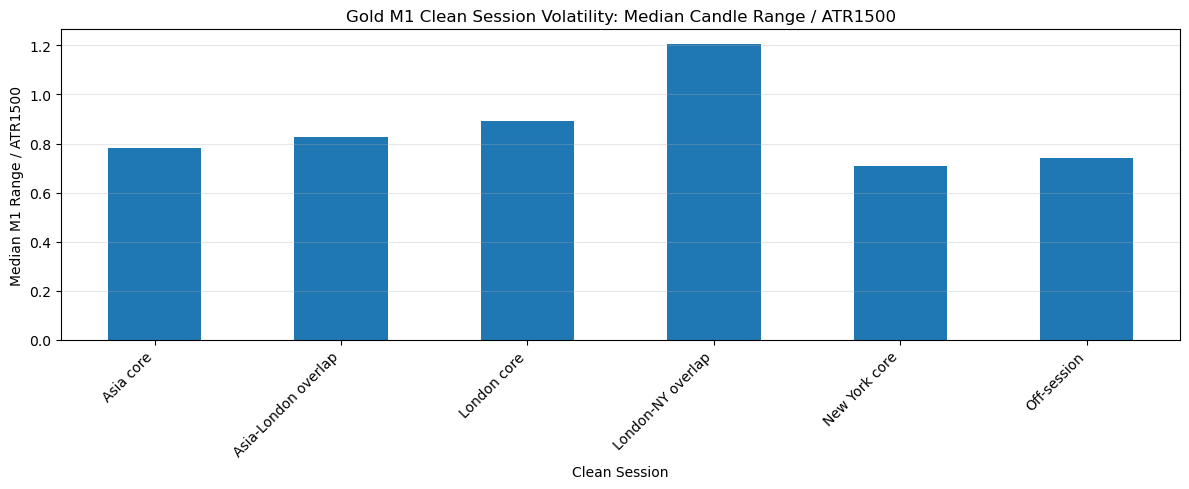

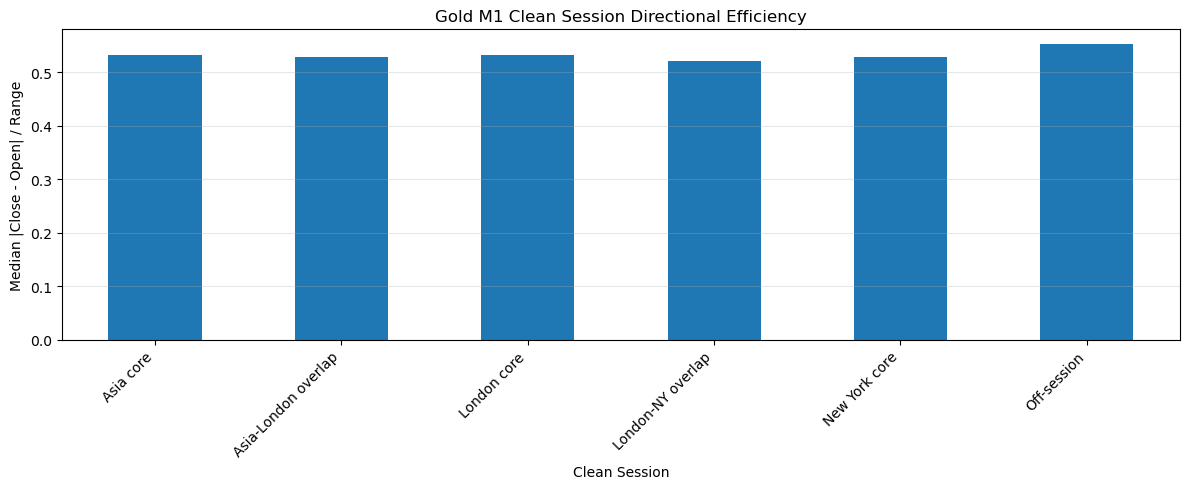

,sessions,median_session_range_atr1500,mean_session_range_atr1500,p75_session_range_atr1500,p90_session_range_atr1500,median_range_atr1500_per_hour,mean_range_atr1500_per_hour,median_raw_range,mean_raw_range,median_duration_hours
session_clean,,,,,,,,,,
Asia core,65,22.400277,24.809154,29.306004,38.854555,3.200040,3.556591,60.16,71.916615,7.000000
Asia-London overlap,65,9.849968,10.909755,13.196044,15.957543,4.924984,5.454878,27.09,31.563231,2.000000
London core,65,17.150218,21.158943,24.323332,33.660130,3.850451,4.825000,46.66,61.638154,4.500000
London-NY overlap,64,17.723055,18.742096,22.013702,26.551182,7.089222,7.496838,50.53,55.899531,2.500000
New York core,64,15.379645,20.618664,22.601922,39.155613,3.091462,4.156344,43.20,62.289375,4.983333
Off-session,64,10.020485,12.510942,13.875890,25.387699,5.040517,6.287324,27.55,37.688594,1.983333


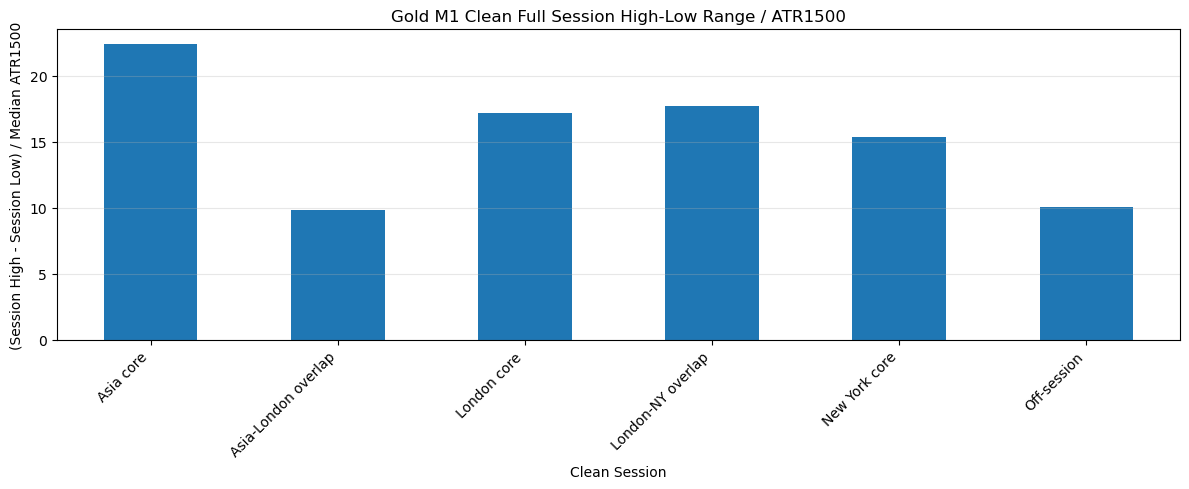

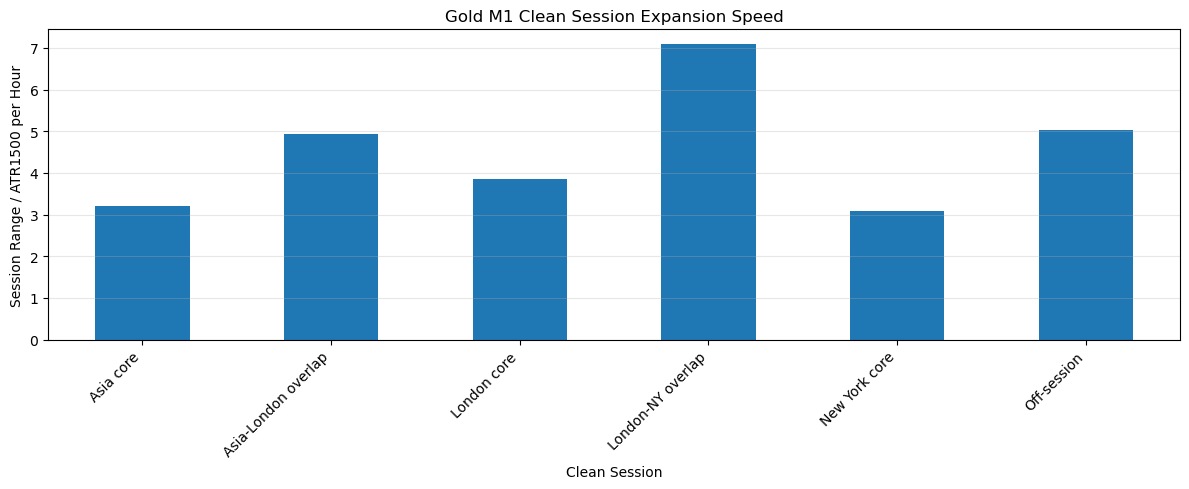

C:\Users\amirj\AppData\Local\Temp\ipykernel_6048\337085302.py:213: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


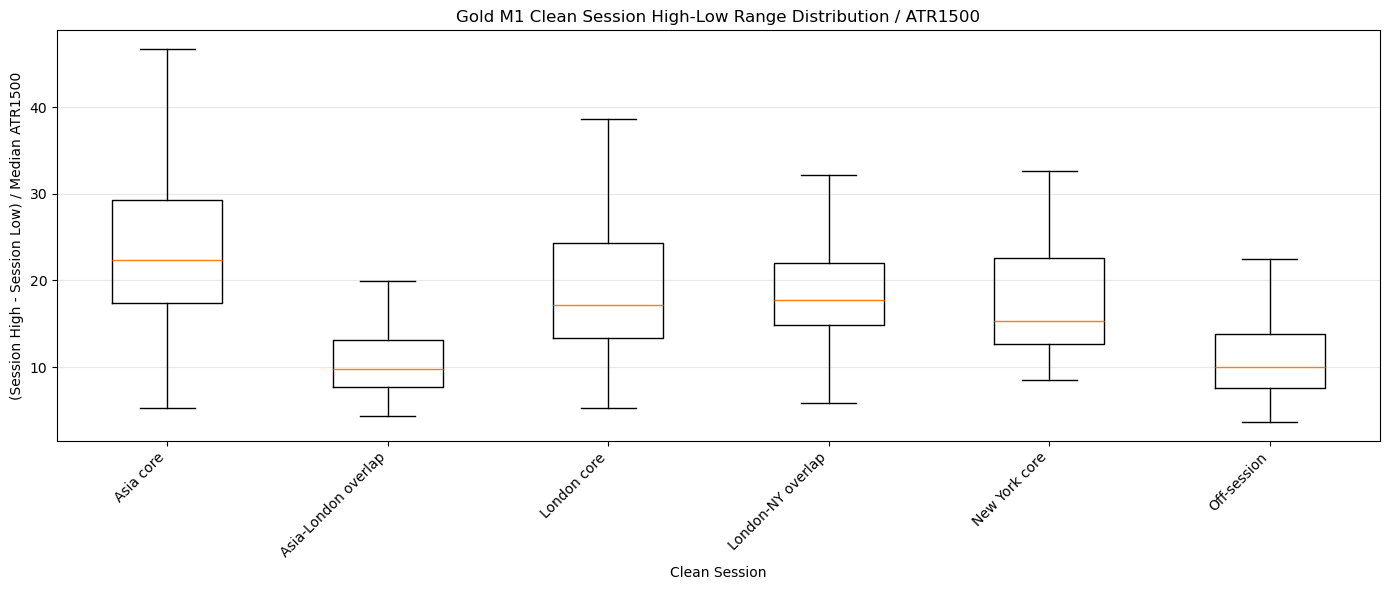

In [52]:
# =========================
# M1 Clean Non-Overlapping Session Analysis
# =========================

m1_clean = d.copy()

# Make sure broker_time exists
m1_clean["broker_time"] = pd.to_datetime(m1_clean["broker_time"])

def minutes_since_midnight(ts):
    return ts.hour * 60 + ts.minute

m1_clean["minute_of_day"] = m1_clean["broker_time"].apply(minutes_since_midnight)
m1_clean["date"] = m1_clean["broker_time"].dt.date

# Broker time UTC+03:00
# Clean non-overlapping session structure:
#
# Off-session:         01:00 - 03:00
# Asia core:           03:00 - 10:00
# Asia-London overlap: 10:00 - 12:00
# London core:         12:00 - 16:30
# London-NY overlap:   16:30 - 19:00
# New York core:       19:00 - 01:00

def clean_session_label_m1(m):
    if 3 * 60 <= m < 10 * 60:
        return "Asia core"
    elif 10 * 60 <= m < 12 * 60:
        return "Asia-London overlap"
    elif 12 * 60 <= m < 16 * 60 + 30:
        return "London core"
    elif 16 * 60 + 30 <= m < 19 * 60:
        return "London-NY overlap"
    elif m >= 19 * 60 or m < 1 * 60:
        return "New York core"
    else:
        return "Off-session"

m1_clean["session_clean"] = m1_clean["minute_of_day"].apply(clean_session_label_m1)

session_order_clean = [
    "Asia core",
    "Asia-London overlap",
    "London core",
    "London-NY overlap",
    "New York core",
    "Off-session"
]

m1_clean["session_clean"] = pd.Categorical(
    m1_clean["session_clean"],
    categories=session_order_clean,
    ordered=True
)

# =========================
# 1. Candle-level volatility by clean session
# =========================

m1_clean["body_atr1500"] = m1_clean["body_raw"] / m1_clean["atr1500"]

m1_clean_session_stats = (
    m1_clean
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=["range_atr1500", "body_atr1500", "directional_efficiency"])
    .groupby("session_clean", observed=False)
    .agg(
        candles=("range_atr1500", "count"),

        median_range_atr1500=("range_atr1500", "median"),
        mean_range_atr1500=("range_atr1500", "mean"),
        p75_range_atr1500=("range_atr1500", lambda x: x.quantile(0.75)),
        p90_range_atr1500=("range_atr1500", lambda x: x.quantile(0.90)),

        median_body_atr1500=("body_atr1500", "median"),
        median_directional_efficiency=("directional_efficiency", "median"),
        median_wick_ratio=("wick_ratio", "median"),

        median_tick_volume=("tick_volume", "median"),
        mean_tick_volume=("tick_volume", "mean"),
    )
)

display(m1_clean_session_stats)

# Bar plot: clean session candle-level volatility
plt.figure(figsize=(12, 5))

m1_clean_session_stats["median_range_atr1500"].plot(kind="bar")

plt.title("Gold M1 Clean Session Volatility: Median Candle Range / ATR1500")
plt.xlabel("Clean Session")
plt.ylabel("Median M1 Range / ATR1500")
plt.grid(True, axis="y", alpha=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Bar plot: clean session directional efficiency
plt.figure(figsize=(12, 5))

m1_clean_session_stats["median_directional_efficiency"].plot(kind="bar")

plt.title("Gold M1 Clean Session Directional Efficiency")
plt.xlabel("Clean Session")
plt.ylabel("Median |Close - Open| / Range")
plt.grid(True, axis="y", alpha=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# =========================
# 2. Full clean session high-low range normalized by ATR1500
# =========================

m1_clean_session_ranges = (
    m1_clean
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=["atr1500"])
    .groupby(["date", "session_clean"], observed=False)
    .agg(
        session_high=("high", "max"),
        session_low=("low", "min"),
        median_atr1500=("atr1500", "median"),
        candles=("close", "count")
    )
    .reset_index()
)

m1_clean_session_ranges["session_range"] = (
    m1_clean_session_ranges["session_high"] - m1_clean_session_ranges["session_low"]
)

m1_clean_session_ranges["session_range_atr1500"] = (
    m1_clean_session_ranges["session_range"] / m1_clean_session_ranges["median_atr1500"]
)

# Minimum 30 M1 candles = 30 minutes
m1_clean_session_ranges = m1_clean_session_ranges[
    m1_clean_session_ranges["candles"] >= 30
].copy()

# Duration-adjusted metric
m1_clean_session_ranges["duration_hours"] = (
    m1_clean_session_ranges["candles"] / 60
)

m1_clean_session_ranges["session_range_atr1500_per_hour"] = (
    m1_clean_session_ranges["session_range_atr1500"]
    / m1_clean_session_ranges["duration_hours"]
)

m1_clean_session_range_summary = (
    m1_clean_session_ranges
    .groupby("session_clean", observed=False)
    .agg(
        sessions=("session_range_atr1500", "count"),

        median_session_range_atr1500=("session_range_atr1500", "median"),
        mean_session_range_atr1500=("session_range_atr1500", "mean"),
        p75_session_range_atr1500=("session_range_atr1500", lambda x: x.quantile(0.75)),
        p90_session_range_atr1500=("session_range_atr1500", lambda x: x.quantile(0.90)),

        median_range_atr1500_per_hour=("session_range_atr1500_per_hour", "median"),
        mean_range_atr1500_per_hour=("session_range_atr1500_per_hour", "mean"),

        median_raw_range=("session_range", "median"),
        mean_raw_range=("session_range", "mean"),
        median_duration_hours=("duration_hours", "median"),
    )
)

display(m1_clean_session_range_summary)

# Bar plot: full session high-low range
plt.figure(figsize=(12, 5))

m1_clean_session_range_summary["median_session_range_atr1500"].plot(kind="bar")

plt.title("Gold M1 Clean Full Session High-Low Range / ATR1500")
plt.xlabel("Clean Session")
plt.ylabel("(Session High - Session Low) / Median ATR1500")
plt.grid(True, axis="y", alpha=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Bar plot: duration-adjusted session expansion
plt.figure(figsize=(12, 5))

m1_clean_session_range_summary["median_range_atr1500_per_hour"].plot(kind="bar")

plt.title("Gold M1 Clean Session Expansion Speed")
plt.xlabel("Clean Session")
plt.ylabel("Session Range / ATR1500 per Hour")
plt.grid(True, axis="y", alpha=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Boxplot: full clean session range distribution
m1_plot_data = [
    m1_clean_session_ranges.loc[
        m1_clean_session_ranges["session_clean"] == s,
        "session_range_atr1500"
    ].dropna()
    for s in session_order_clean
]

plt.figure(figsize=(14, 6))

plt.boxplot(
    m1_plot_data,
    labels=session_order_clean,
    showfliers=False
)

plt.title("Gold M1 Clean Session High-Low Range Distribution / ATR1500")
plt.xlabel("Clean Session")
plt.ylabel("(Session High - Session Low) / Median ATR1500")
plt.grid(True, axis="y", alpha=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()